# Le rôle des ouvertures aux échecs, inspiré du Jeu de la dame

[![Ouvrir dans Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Hadrienfonrojet/ANALYSE-MARCHE-/blob/main/QueensGambit.ipynb)

Dans la série *Le Jeu de la dame*, Beth Harmon gagne en rejouant les lignes qu’elle a travaillées. Ce projet part de cette intuition, sans étudier la série elle-même : **répéter une ouverture dépend-il de l'issue de la partie précédente ?** Nous la testons sur des parties réelles de la plateforme Lichess.

### Problématique

**Comment les taux de victoire, de défaite et de nulle varient-ils selon l’ouverture, la couleur, la période et la répétition d’une même stratégie ?**

### Questions étudiées

*Partie 3 — Premières statistiques descriptives*

1. Quel est le profil des parties collectées : niveau des joueurs, résultats, avantage de la couleur ?
2. Avec quelles familles d’ouverture les parties sont-elles le plus souvent gagnées, perdues ou nulles ?
3. Ces proportions évoluent-elles dans le temps : sur une fenêtre annoncée avant l’analyse, puis semaine par semaine ?
4. Quelle est la plus longue série de victoires, de défaites et de nulles avec une même famille ?

*Partie 4 — Répéter l’ouverture après un succès*

5. Répète-t-on plus souvent sa famille d’ouverture après une victoire qu’après une défaite ?
6. Après une victoire, répéter la même famille est-il associé à une nouvelle victoire ?
7. Ce lien résiste-t-il quand on tient compte du niveau des joueurs ?

*Partie 5 — Les autres causes possibles*

8. Garder la même couleur, ou la même famille **et** la même couleur, change-t-il les chances de gagner ?
9. Ces effets résistent-ils quand on les étudie ensemble, à niveau égal et à l’intérieur d’un même joueur ?
10. La fatigue ou l’enchaînement des victoires jouent-ils un rôle au fil d’une session ?
11. Contre le même adversaire, vaut-il mieux garder son ouverture ou en changer ?

### Comment lire ce notebook

Chaque étape suit trois blocs : **ce que l’on fait et pourquoi**, **le code**, puis **l’interprétation** de la sortie. Un bloc de code ne fait qu’une chose et ne produit qu’une sortie. Les chiffres commentés portent sur la collecte publiée `donnees/parties_1an.parquet`. Ce sont des **associations** observées : un joueur choisit son ouverture et sa cadence, et ces choix peuvent refléter sa forme du moment.

### Plan

**Partie 1 — Collecter les données**
1.1 Pourquoi une API · 1.2 Choisir les comptes · 1.3 Télécharger les parties · 1.4 Conserver la collecte · 1.5 Préparer l’environnement · 1.6 Charger les parties · 1.7 Ce que la collecte a ramené

**Partie 2 — Nettoyer et construire la base**
2.1 Le référentiel des ouvertures · 2.2 Identifier l’ouverture · 2.3 Nettoyer · 2.4 Contrôler les résultats

**Partie 3 — Premières statistiques descriptives**
3.1 Taille et période · 3.2 Niveau des joueurs · 3.3 Résultats · 3.4 La couleur · 3.5 Les familles d’ouverture · 3.6 Une fenêtre de temps · 3.7 Les séries

**Partie 4 — Répéter l’ouverture après un succès**
4.1 Préparer les enchaînements · 4.2 Répéter ou changer de famille · 4.3 Après une victoire : le χ² · 4.4 Trois définitions de la partie suivante · 4.5 Fisher et bootstrap · 4.6 Les régressions

**Partie 5 — Les autres causes possibles**
5.1 Garder la même couleur · 5.2 Même famille et même couleur · 5.3 Une régression qui réunit tout · 5.4 La session et la main chaude · 5.5 Contre le même adversaire · 5.6 Bilan des tests

**Conclusion et sauvegarde**

# Partie 1 — Collecter les données

La collecte ne s’exécute pas dans ce notebook : elle interroge l’API de Lichess pendant 15 à 45 minutes. Elle est lancée une fois, depuis un terminal, par `Master_file.py`. Le notebook relit ensuite le fichier qu’elle a produit. Les sections 1.1 à 1.4 décrivent comment ce fichier a été fabriqué ; les sections 1.5 à 1.7 le chargent et regardent ce qu’il contient.

## 1.1 Pourquoi une API plutôt que du web scraping

Afin de télécharger les données nécessaires à notre analyse, nous avons choisi d'utiliser l'API Lichess, qui est publique, plutôt que de passer par du web scraping. En effet, en se connectant à notre compte Lichess, nous avons obtenu un jeton de connexion et l'avons donné dans les paramètres de config pour que nous puissions échanger par fichier json.
Nous avons choisi un format NDJSON afin d'éviter les bugs de collecte de données, et car cela permet une communication partie par partie (une partie par ligne json), plutôt que de renvoyer un fichier global avec une réponse contenant toutes les parties. 

```python
payload = "".join(
    json.dumps(g, ensure_ascii=False) + "\n"
    for g in games
).encode("utf-8")
```

## 1.2 Choisir les comptes : trois graines et une marche aléatoire

On part de trois comptes « graines » : `macaquezizi`, `T34USSR` et `lucascrotti`. Ces comptes sont des utilisateurs possédant un ELO différent, ce qui nous permet de couvrir des niveaux de jeu variés ; l’échantillon reste toutefois propre à ces comptes et à leurs adversaires, et ne représente pas l’ensemble des joueurs du site. Pour chaque graine, on utilise la fonction discover_users_random_walk(), qui lit les 10 dernières parties du compte, relève ses adversaires, en tire quelques-uns au hasard, puis on recommence depuis l’un d’eux pour compléter notre dataframe:

```python
candidates = [name for name in get_recent_opponents(current, token) if name not in known]
batch = rng.sample(candidates, take)      # tirer au hasard des adversaires encore inconnus
users.extend(batch)
current = rng.choice(batch)               # repartir de l’un d’eux
```

**Pourquoi.** Lichess ne fournit pas de liste de joueurs. Se déplacer de joueur en adversaire donne des comptes actifs, de niveaux variés. La graine aléatoire est fixée à 73 (`random.Random(73)`) : la même collecte relancée choisit les mêmes comptes. 

## 1.3 Télécharger les parties de chaque compte

Pour chaque compte et chaque cadence (bullet, blitz, rapid, classical), `extract_games_user()` (fichier `import_parties.py`) appelle l’adresse `https://lichess.org/api/games/user/{pseudo}` avec ces paramètres :

```python
params = {
    "max": nb_parties,          # plafond de parties par compte et par cadence
    "rated": "true",            # seulement les parties classées (avec Elo)
    "perfType": format_partie,  # une cadence à la fois
    "opening": "true",          # le nom d’ouverture donné par Lichess
    "moves": "true",            # la suite des coups, pour identifier nous-mêmes l’ouverture
    "finished": "true",         # seulement les parties terminées
}
```

**Pourquoi.** Les parties classées ont un Elo, indispensable pour comparer des joueurs de niveaux différents. Les coups permettent d’identifier l’ouverture avec notre propre règle (partie 2). 

## 1.4 Conserver et partager la collecte

Chaque réponse brute est enregistrée telle quelle (`api_<pseudo>_<cadence>.ndjson`) avec une fiche de contrôle (paramètres), sans jamais écraser un fichier existant. `Master_file.py` réunit tout dans `dfs_games_brut.parquet`, puis, avec l’option `--upload`, copie la collecte sur le stockage du SSP Cloud. Garder la réponse brute permet de refaire toute l’analyse sans réinterroger Lichess, et de prouver sur quelles données elle porte si bien qu'un utilisateur externe aura le même jeu de données que nous sur son test. Le fichier `donnees/parties_1an.parquet` publié dans le dépôt est cette base brute.

La commande qui a produit cette collecte, lancée dans un terminal du SSP Cloud avec `USERS_PER_SEED=10` et `GAMES_PER_FORMAT=300` dans le fichier `.env` (une dizaine de comptes par graine, au plus 300 parties par compte et par cadence, sur un an) :

```bash
python Master_file.py --collect --discover --since 2025-11-25 --until 2026-11-25 --debut 2026-05-01 --fin 2026-11-01 --upload
```

## 1.5 Préparer l’environnement

### 1.5.1 Importer les bibliothèques de calcul

On prépare l’environnement et on importe toutes les bibliothèques nécessaires à notre analyse. 


| Bibliothèque | Rôle dans le projet |
|---|---|
| `pathlib`, `os`, `sys`, `subprocess` | Se placer dans le bon dossier ; sur Colab, cloner le dépôt et installer les dépendances |
| `hashlib`, `io`, `json` | Empreintes des fichiers, lecture d’un fichier reçu du cloud, fichiers de paramètres |
| `numpy`, `pandas` | Calcul numérique et manipulation des tables de parties |
| `matplotlib`, `IPython.display` | Graphiques et affichage des tableaux |
| `scipy`, `statsmodels` | Tests statistiques (χ², Fisher) et régressions |

Sur le SSP Cloud ou en local, le bloc ne fait qu’importer. Sur Colab, où le dépôt n’est pas présent, il le clone depuis GitHub et installe `requirements.txt`.

In [1]:
from pathlib import Path
import os
import sys
import subprocess
import warnings
import hashlib
import io
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy.stats import chi2_contingency, fisher_exact
from statsmodels.stats.multitest import multipletests
from IPython.display import display, Image
warnings.filterwarnings("ignore", category=FutureWarning)

print("Python", sys.version.split()[0], "| pandas", pd.__version__, "| NumPy", np.__version__)

Python 3.13.18 | pandas 3.1.1 | NumPy 2.5.5


In [2]:
# Se placer à la racine du projet (le dossier qui contient config.py).
if not Path("config.py").is_file() and Path("../config.py").is_file():
    os.chdir("..")
if not Path("config.py").is_file():  # Cas Colab : le dépôt n’est pas encore là.
    target = Path("/content/jeu_de_la_dame")
    if not target.exists():
        subprocess.run(["git", "clone", "https://github.com/Hadrienfonrojet/ANALYSE-MARCHE-.git", str(target)], check=True)
    os.chdir(target)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
sys.path.insert(0, str(Path.cwd()))  # Rendre les modules du projet importables.


**Interprétation.** L’environnement est complet : Python, pandas 3 et NumPy 2 sont chargés, ainsi que les bibliothèques de tests (`scipy`) et de régression (`statsmodels`). Les versions sont aussi enregistrées dans la fiche de reproductibilité à la fin du notebook.

### 1.5.2 Charger la configuration, socle du projet

Le fichier `config.py` est la base de tout le projet : tous les autres fichiers le lisent. Il contient :

- les **chemins** (`Data/`, `Resultats/`, `References/`) ;
- les **paramètres de collecte** : comptes graines, cadences, nombre de parties par cadence, graine aléatoire 73 ;
- la **version figée** du référentiel des ouvertures et la profondeur d’identification (5 à 10 coups) ;
- le **niveau d’analyse** des ouvertures (`NIVEAU_OUVERTURE = "famille"`) ;
- la lecture du fichier privé `.env`, qui garde le jeton Lichess et les clés du stockage hors du code et hors de GitHub.

Modifier un réglage dans `config.py` change le comportement de toute la chaîne, sans toucher aux autres fichiers.

In [3]:
import config as cfg

# Modules du projet : chacun s’appuie sur les réglages de config.py.
from import_ouvertures import creer_openings
from Master_file import identifier_parties
from nettoyage import preparer_parties
from analyse import (
    statistiques_ouvertures, statistiques_temporelles, series_resultats,
    regressions_lineaires, preparer_regressions, exporter_tableaux,
    tests_repetition, tracer_resultats, ecrire_manifeste,
)
from Analyse_repetition_ouverture import (
    preparer_cadres, taux_apres_victoire, tester_table, bootstrap_joueurs,
)

print("Version du référentiel d’ouvertures :", cfg.OPENINGS_REFERENCE_REV[:8])
print("Niveau d’analyse des ouvertures :", cfg.NIVEAU_OUVERTURE)
print("Identification sur", cfg.OPENING_MIN_FULLMOVES, "à", cfg.OPENING_MAX_FULLMOVES, "coups | graine aléatoire :", cfg.RANDOM_SEED)

Version du référentiel d’ouvertures : 712a58be
Niveau d’analyse des ouvertures : famille
Identification sur 5 à 10 coups | graine aléatoire : 73


**Interprétation.** La configuration confirme les trois réglages qui conditionnent tous les résultats : le référentiel d’ouvertures est figé à la version `712a58be`, les ouvertures sont étudiées au niveau de la famille d'ouverture, et l’identification rejoue entre 5 et 10 coups (c’est-à-dire qu’une ouverture est reconnue si les 5 premiers coups correspondent au schéma théorique de cette dernière). La graine aléatoire 73 rend la sélection des comptes reproductible, et identique à tous les utilisateurs du notebook.

### 1.5.3 Fixer les paramètres de l’analyse

**Objectif.** Toutes les décisions qui changent les résultats sont réunies dans une seule cellule et annoncées avant de regarder les données : la source, la fenêtre de temps de la section 3.6, l’ouverture étudiée en détail et le seuil d’affichage.

**Deux façons d’obtenir les parties**, selon `SOURCE` :

- **`"fichier"` — les parties sont déjà dans le dépôt.** La collecte a été faite une fois, puis le fichier `donnees/parties_1an.parquet` a été publié sur GitHub avec le code. Les parties y sont stockées « en dur » : n’importe qui peut relancer le notebook, sans réseau et sans identifiant, et obtenir exactement les mêmes chiffres. C’est le mode par défaut, celui qui garantit la reproductibilité.
- **`"s3"` — les parties sont dans le cloud.** Chaque collecte est aussi sauvegardée sur le stockage du SSP Cloud (`s3://hadrien2703/diffusion/projet_ouvertures/<collecte>/`). Ce mode va les chercher à distance. Il sert pour une collecte plus récente ou plus grosse que celle du dépôt ; il demande les clés d’accès du SSP Cloud et le nom de la collecte dans `S3_RUN_ID`.

In [4]:
SOURCE = "fichier"                            # "fichier" : parties publiées dans le dépôt ; "s3" : parties du stockage SSP Cloud.
LOCAL_FILE = "donnees/parties_1an.parquet"    # Utilisé si SOURCE = "fichier".
S3_RUN_ID = ""                                # Nom du dossier de collecte, utilisé si SOURCE = "s3".
DEBUT = "2026-05-01"                          # Exercice 2 : début inclus (UTC).
FIN = "2026-11-01"                            # Exercice 2 : fin exclue (UTC).
OUVERTURE = "Sicilian Defense"                # Famille étudiée en détail.
MIN_PARTIES = 20                              # Seuil d’affichage des familles dans les tableaux.

print("Source :", SOURCE, "|", LOCAL_FILE if SOURCE == "fichier" else S3_RUN_ID)
print("Fenêtre de l’exercice 2 :", DEBUT, "inclus →", FIN, "exclu")

Source : fichier | donnees/parties_1an.parquet
Fenêtre de l’exercice 2 : 2026-05-01 inclus → 2026-11-01 exclu


## 1.6 Charger les parties

 `cfg.create_run()` ouvre d’abord un dossier neuf `Collectes/<date>_<identifiant>/` : les résultats de cette exécution y seront rangés sans jamais écraser une exécution précédente. Ensuite :

- **si les parties sont dans le dépôt** (`"fichier"`), `pd.read_parquet` lit directement `donnees/parties_1an.parquet` : rien n’est téléchargé, la lecture est instantanée et identique pour tous ;
- **si elles sont dans le cloud** (`"s3"`), le client du SSP Cloud télécharge `dfs_games_brut.parquet` de la collecte demandée, puis pandas le lit en mémoire.

Dans les deux cas, on obtient la même table `brut` : une ligne par partie et par compte suivi. La suite du notebook ne dépend donc pas de la provenance des données.

In [5]:
cfg.create_run()  # Dossier neuf pour les résultats de cette exécution.

if SOURCE == "fichier":
    # Cas 1 : les parties sont déjà publiées dans le dépôt.
    path = Path(LOCAL_FILE)
    brut = pd.read_csv(path) if path.suffix.lower() == ".csv" else pd.read_parquet(path)
elif SOURCE == "s3":
    # Cas 2 : aller chercher la collecte sur le stockage SSP Cloud.
    if not S3_RUN_ID or Path(S3_RUN_ID).name != S3_RUN_ID or S3_RUN_ID in {".", ".."}:
        raise ValueError("Préciser un identifiant simple de collecte S3")
    from Stockage_SSPCloud import client
    key = f"{cfg.S3_PREFIX}/{S3_RUN_ID}/Data/dfs_games_brut.parquet"
    response = client().get_object(Bucket=cfg.S3_BUCKET, Key=key)
    try:
        brut = pd.read_parquet(io.BytesIO(response["Body"].read()))
    finally:
        response["Body"].close()
else:
    raise ValueError("SOURCE doit être fichier ou s3")

print("Lignes brutes :", len(brut), "| colonnes :", brut.shape[1])
print(brut[["user_id", "game_id", "format_partie", "result", "rating", "opponent_rating"]].head(3).to_string(index=False))

Lignes brutes : 13727 | colonnes : 17
      user_id  game_id format_partie result  rating  opponent_rating
oleg_s_k_2022 0bmyTnAG        bullet    Win    1254             1235
oleg_s_k_2022 Bko4eiNI        bullet   Loss    1273             1245
oleg_s_k_2022 5t8g3KoW        bullet    Win    1252             1299


**Interprétation.** La base brute contient **13 727 lignes et 17 colonnes**. Chaque ligne est une partie vue par un compte suivi : `user_id` identifie ce compte, `game_id` la partie. Les trois premières lignes sont les trois parties les plus récentes extraites. On observe les catégories qui influenceront notre analyse : le rating, le type de partie qui influe sur les ouvertures, et le résultat.

## 1.7 Ce que la collecte a ramené

Avant de nettoyer, on regarde la base brute telle que l’API l’a renvoyée, afin de repérer la trace des choix de collecte (graines, plafond par cadence, parties les plus récentes en premier) et de savoir ce que l’échantillon représente.

### 1.7.1 Combien de parties par compte ?

On compte les parties jouées par compte afin d'étudier les probabilités de victoires et observer quels comptes sont les plus représentatifs à l'analyse. 


In [6]:
par_compte = brut["user_id"].value_counts()

print("Comptes collectés :", brut["user_id"].nunique())
display(par_compte.head(5).to_frame("parties"))
print("Total de parties :", par_compte.sum())

Comptes collectés : 30


,parties
user_id,
lucascrotti,1098
ojaijoao,1046
peonzen,832
deder87,797
gulf_titans,773


Total de parties : 13727


**Interprétation.** La collecte a ramené **30 comptes** et 13 727 parties, mais très inégalement. Les cinq comptes les plus actifs (`lucascrotti` 1 098, `ojaijoao` 1 046, `peonzen` 832, `deder87` 797, `gulf_titans` 773) réunissent un tiers des parties, alors que quelques comptes n’en ont qu’une poignée (3 pour `igetmykingoutfirst`, 9 pour `killerchess1`). Les comptes les plus actifs pèsent donc beaucoup plus que les autres dans les taux de victoire : c’est pourquoi le notebook calcule aussi des taux **équipondérés** par joueur et des modèles **avec effet fixe joueur**.

### 1.7.2 Combien de parties par cadence ?

Ensuite on s'intéresse au nombre de parties par cadence afin de pouvoir distinguer les effets des ouvertures. En effet, en fonction du mode de jeu, un joueur expérimenté ne jouera certainement pas la même ouverture car certaines sont moins efficaces. D'autre part, en parties rapides (bullet) on réagit plus vite à une attaque de l'adversaire, et on peut sortir plus rapidement de l'ouverture. 

In [7]:
display(pd.crosstab(brut["user_id"], brut["format_partie"], margins=True, margins_name="Total"))

format_partie,blitz,bullet,classical,rapid,Total
user_id,,,,,
bcow,0,300,0,0,300
brilliant-enterprise,7,27,15,33,82
deder87,300,300,3,194,797
gulf_titans,300,300,0,173,773
harilao,300,42,0,300,642
houssemam,1,0,0,35,36
igetmykingoutfirst,3,0,0,0,3
jss111810,180,300,1,128,609
killerchess1,0,9,0,0,9


**Interprétation.** Les quatre cadences sont bien représentées, sauf la cadence classique : rapid 4 393 parties, bullet 4 186, blitz 4 115, classical 1 033 (presque toutes jouées par quatre comptes). Beaucoup de comptes atteignent exactement **300 parties**, le plafond fixé par cadence : pour eux, l’historique est tronqué et ne remonte que de quelques semaines ou mois. Les ouvertures ne se jouent pas de la même façon en bullet et en classique, d’où le contrôle de la cadence dans les régressions.

### 1.7.3 Quelle période chaque compte couvre-t-il ?

On convertit la date de début de chaque partie (en millisecondes depuis 1970, colonne `timestamp_ms`) en date lisible, puis on relève la première et la dernière partie de chaque compte.

**Pourquoi.** L’API renvoie les parties les plus récentes. Un compte très actif atteint son plafond en quelques jours ; un compte peu actif remonte sur plusieurs semaines. La période couverte n’est donc pas la même pour tous, ce qui compte pour la fenêtre de temps de la section 3.6.

In [8]:
dates_brutes = pd.to_datetime(brut["timestamp_ms"], unit="ms", utc=True)
periode = dates_brutes.groupby(brut["user_id"]).agg(premiere="min", derniere="max")
periode["jours_couverts"] = (periode["derniere"] - periode["premiere"]).dt.days
display(periode.sort_values("jours_couverts"))

,premiere,derniere,jours_couverts
user_id,,,
igetmykingoutfirst,2026-08-31 06:17:02.786+00:00,2026-08-31 06:33:00.338+00:00,0
brilliant-enterprise,2026-11-21 02:03:45.264+00:00,2026-11-24 02:59:30.740+00:00,3
killerchess1,2026-10-29 12:04:51.405+00:00,2026-11-05 06:04:00.019+00:00,6
houssemam,2026-09-13 10:13:19.409+00:00,2026-10-09 19:26:55.819+00:00,26
serg_tourn,2026-09-18 22:07:33.189+00:00,2026-11-24 23:41:04.477+00:00,67
smitoo,2026-04-21 08:36:48.055+00:00,2026-07-23 08:41:36.315+00:00,93
terra4nova,2026-07-20 10:12:14.581+00:00,2026-11-24 21:02:17.032+00:00,127
strezh_ka,2026-07-14 09:17:01.332+00:00,2026-11-21 18:11:11.520+00:00,130
bcow,2026-07-06 03:54:10.977+00:00,2026-11-24 23:35:53.761+00:00,141


**Interprétation.** La période couverte va de quelques jours (`igetmykingoutfirst`, `brilliant-enterprise`, `killerchess1`) à presque un an : une quinzaine de comptes remontent jusqu’en décembre 2025. Les comptes très actifs atteignent leur plafond de 300 parties en quelques semaines (`serg_tourn` : 600 parties en 67 jours), alors que les comptes moins actifs remontent loin. Conséquence directe pour la fenêtre de temps (section 3.6) : les mois récents contiennent beaucoup plus de comptes et de parties (septembre à novembre font 59 % de la base) ; deux mois ne comparent donc pas les mêmes joueurs.

### 1.7.4 Comment les parties se sont-elles terminées ?

On compte les parties selon leur statut de fin (`status`) et selon leur variante (`variant`).
Certaines parties n’ont pas de vrai résultat (partie annulée avant le premier coup) ou ne se jouent pas avec les règles classiques (Chess960, où la position de départ est tirée au hasard). Elles doivent être retirées. Ce comptage montre ce que le nettoyage va enlever, et pourquoi.

In [9]:
display(pd.concat({"statut de fin": brut["status"].value_counts(), "variante": brut["variant"].value_counts()}).to_frame("parties"))

parties
statut de fin resign                        6458
              mate                          3176
              outoftime                     3141
              draw                           482
              timeout                        305
              stalemate                       88
              noStart                         72
              cheat                            3
              insufficientMaterialClaim        2
variante      standard                     13509
              fromPosition                   218

**Interprétation.** La plupart des parties se terminent par abandon (6 458), mat (3 176) ou dépassement du temps (3 141) ; les nulles (482 par accord, 88 pats) sont rares. Deux catégories sont à écarter : les **72 parties non commencées** (`noStart`) et les **218 parties en variante `fromPosition`**, qui partent d’une position choisie et n’ont donc pas d’ouverture.

# Partie 2 — Nettoyer et construire la base

On passe de la base brute à la base d’analyse en trois étapes, chacune dans son propre bloc : **charger le référentiel des ouvertures**, **identifier l’ouverture de chaque partie**, puis **nettoyer**. `brut` contient la source, `identifiees` ajoute la classification, et `parties` est la table nettoyée sur laquelle portent toutes les analyses.

## 2.1 Charger le référentiel officiel des ouvertures

 `creer_openings()` lit les cinq fichiers officiels de Lichess (`a.tsv` à `e.tsv`), figés à une version précise et rangés dans `References/`. Pour chaque ouverture, elle rejoue la suite de coups officielle et garde la position d’échiquier atteinte.

On utilise la base de données Lichess pour avoir un référentiel commun sur les ouvertures, en raison du grand nombre de variantes et de noms différents. 

In [10]:
reference = creer_openings()
print("Référentiel :", len(reference), "ouvertures officielles")
display(reference[["eco", "name", "family"]].head(5))

Référentiel : 3865 ouvertures officielles


,eco,name,family
0,A00,Amar Opening,Amar Opening
1,A00,Amar Opening: Paris Gambit,Amar Opening
2,A00,"Amar Opening: Paris Gambit, Gent Gambit",Amar Opening
3,A00,Amsterdam Attack,Amsterdam Attack
4,A00,Anderssen's Opening,Anderssen's Opening


**Interprétation.** Le référentiel compte **3 865 ouvertures officielles**. Chaque nom complet (« Amar Opening: Paris Gambit ») est rattaché à une **famille** (« Amar Opening ») : c’est ce niveau qu’on analyse, car les variantes trop fines diviseraient les parties en groupes minuscules.

## 2.2 Identifier l’ouverture de chaque partie

`identifier_parties()` rejoue les 10 premiers coups de chaque partie et cherche, à chaque demi-coup, si la position atteinte figure dans le référentiel. Elle retient la variante la plus précise atteinte. Une partie de moins de 5 coups reste « inconnue », en raison de notre choix de config.

**Pourquoi comparer des positions plutôt que des coups.** Deux ordres de coups différents peuvent mener à la même position  : ils reçoivent le même nom. Et nous appliquons la même règle à toutes les parties, au lieu de dépendre du nom fourni par l’API.

In [11]:
identifiees = identifier_parties(brut, reference)
display(identifiees["opening_identification_status"].value_counts().to_frame("parties"))

,parties
opening_identification_status,
identifiee,13318
variante_non_standard,218
partie_trop_courte,151
coups_absents,40


**Interprétation.** **13 318 parties sur 13 727 (97 %)** ont une ouverture identifiée par nos propres coups. Les autres sont les 218 variantes non standard, 151 parties trop courtes pour atteindre une position du référentiel et 40 parties sans coups. L’identification est donc quasi complète.

## 2.3 Nettoyer et faire le bilan

`preparer_parties()` harmonise les dates en UTC et les résultats, retire les parties sans résultat, les variantes non standard et les doublons, puis crée les variables d’analyse et regroupe les ouvertures par **famille** (le nom avant « : », par exemple *Sicilian Defense*). Elle renvoie la table `parties` et un `bilan` qui compte chaque opération.

In [12]:
parties, bilan = preparer_parties(identifiees)
print(pd.Series(bilan).to_string())

lignes_brutes                     13727
lignes_invalides_rejetees           271
identifiants_manquants_rejetes        0
doublons_retires                      0
lignes_nettoyees                  13456
parties_uniques                   13443
joueurs                              30
ouvertures_manquantes               138
elo_adverse_manquant                  0
dates_ex_aequo                        0
ruptures_historique                  87
joueurs_chronologie_incertaine        0


**Interprétation.** Le nettoyage rejette **271 lignes invalides** (positions de départ modifiées, parties non commencées ou sans coups) et ne trouve ni doublon ni date ex aequo. Il reste **13 456 lignes**, soit 13 443 parties uniques : 13 parties opposent deux comptes suivis et apparaissent donc deux fois, une fois par joueur. 138 lignes n’ont pas d’ouverture, et **87 ruptures d’historique** signalent un trou dans la suite des parties d’un compte : on ne reliera jamais deux parties de part et d’autre d’une rupture.

## 2.4 Contrôler les variables de résultat

On affiche quelques lignes avec les trois indicateurs de résultat (`win`, `loss`, `draw`, qui valent 0 ou 1) et le score (1 pour une victoire, 0,5 pour une nulle, 0 pour une défaite), puis on vérifie que chaque ligne a exactement un résultat.
La moyenne d’un indicateur 0/1 donne directement un taux : la moyenne de `win` est le taux de victoire. Le contrôle `assert` arrête le notebook si une ligne avait zéro ou deux résultats, ce qui poserait problème dans l'analyse.

In [13]:
colonnes_utiles = ["game_id", "date", "opening_name", "result", "win", "loss", "draw", "score"]
display(parties[colonnes_utiles].head(8))
assert parties[["win", "loss", "draw"]].sum(axis=1).eq(1).all()
print("Une seule des trois colonnes de résultat vaut 1 pour chaque ligne : contrôle réussi.")

,game_id,date,opening_name,result,win,loss,draw,score
0,hIraugYt,2026-07-06 03:54:10.977+00:00,Hungarian Opening,Win,1,0,0,1.0
1,71t293Ko,2026-07-06 04:40:01.002+00:00,Van't Kruijs Opening,Loss,0,1,0,0.0
2,USITtxNc,2026-07-06 04:41:46.769+00:00,Caro-Kann Defense,Loss,0,1,0,0.0
3,je61GnLN,2026-07-06 04:43:39.770+00:00,Sicilian Defense,Win,1,0,0,1.0
4,44Brcqg1,2026-07-06 04:46:18.706+00:00,Hungarian Opening,Win,1,0,0,1.0
5,KBLIl7zj,2026-07-06 04:48:46.159+00:00,Sicilian Defense,Loss,0,1,0,0.0
6,Jq9B0A4E,2026-07-06 04:51:12.227+00:00,Hungarian Opening,Win,1,0,0,1.0
7,jqglO88c,2026-07-06 04:53:49.705+00:00,Sicilian Defense,Win,1,0,0,1.0


Une seule des trois colonnes de résultat vaut 1 pour chaque ligne : contrôle réussi.


**Interprétation.** Chaque partie a exactement un résultat : `win`, `loss` et `draw` sont exclusives, et `score` vaut 1, ½ ou 0. Le contrôle automatique le confirme sur toute la base.

# Partie 3 — Premières statistiques descriptives

On décrit la base nettoyée avant toute recherche de lien : sa taille, le niveau des joueurs, les résultats, l’effet de la couleur, puis les trois exercices demandés (les familles d’ouverture, une fenêtre de temps, les séries). Ces chiffres servent de référence pour les parties 4 et 5.

## 3.1 Taille et période de l’échantillon

On compte séparément les lignes, les parties distinctes et les comptes, puis on relève la période couverte.


In [14]:
print("Lignes :", len(parties), "| parties uniques :", parties.game_id.nunique(),
      "| comptes :", parties.user_id.nunique())
print("Période UTC :", parties.date.min(), "à", parties.date.max())

Lignes : 13456 | parties uniques : 13443 | comptes : 30
Période UTC : 2025-11-25 08:49:07.998000+00:00 à 2026-11-24 23:41:04.477000+00:00


**Interprétation.** La base de travail contient **13 456 lignes de 30 comptes**, du 25 novembre 2025 au 24 novembre 2026 : une année complète, soit onze fois plus de parties que la collecte de test.

## 3.2 Le niveau des joueurs

On résume l’Elo du joueur, celui de l’adversaire, leur écart (`elo_diff` = joueur − adversaire) et le score.
L’Elo mesure le niveau. Si les écarts sont importants, ils expliquent une grande partie des résultats, et il faudra les contrôler avant d’attribuer un effet à l’ouverture.

In [15]:
display(parties[["rating", "opponent_rating", "elo_diff", "score"]].agg(["count", "mean", "std", "min", "max"]).round(3))

,rating,opponent_rating,elo_diff,score
count,13456.000,13456.000,13456.000,13456.000
mean,1950.044,1860.323,89.722,0.585
std,539.141,495.631,252.165,0.481
min,474.000,400.000,-1539.000,0.000
max,2880.000,3064.000,1777.000,1.000


**Interprétation.** Les comptes suivis ont en moyenne **1 950 Elo**, de 474 à 2 880 : tous les niveaux sont représentés. Leurs adversaires sont un peu plus faibles (1 860 en moyenne), si bien que l’écart moyen est de **+90 points** en faveur du compte suivi. Ce biais vient de la collecte : la marche aléatoire tombe sur des comptes très actifs, souvent plus forts que leurs adversaires. Il explique en partie pourquoi les comptes gagnent plus d’une partie sur deux.

On représente un histogramme mesurant la différence de niveau autour des joueurs, en comparant les élos de son adversaire et les siens, afin de voir le déséquilibre entre les parties. Un déséquilibre aura tendance à influer sur l'ouverture, car certaines ouvertures conduisent à des nuls et des échanges de pièces rapides. 

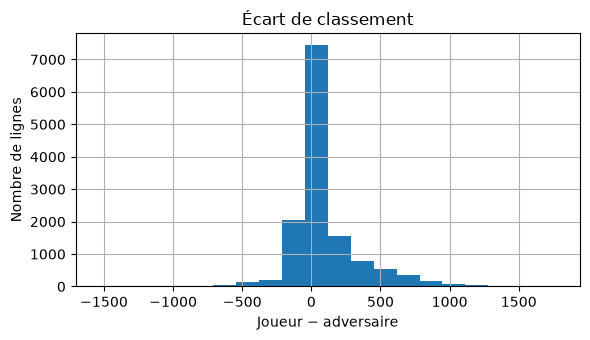

In [16]:
ax = parties.elo_diff.dropna().hist(bins=20, figsize=(6, 3.5))
ax.set(title="Écart de classement", xlabel="Joueur − adversaire", ylabel="Nombre de lignes")
plt.tight_layout()
plt.show()

**Interprétation.** L’écart de classement est centré un peu au-dessus de zéro : la plupart des parties opposent des joueurs proches (écart-type de 252 points), mais quelques parties très déséquilibrées s’étendent jusqu’à ±1 500 points. Comme l’Elo pèse fortement sur le résultat, il faudra toujours comparer à écart de classement égal.

## 3.3 Les résultats et le score

On calcule les taux de victoire, de défaite et de nulle, et le score moyen. Le score donne 1 point à une victoire, 0,5 à une nulle et 0 à une défaite.

In [17]:
print("Taux de victoire :", round(parties.win.mean(), 4))
print("Taux de défaite :", round(parties.loss.mean(), 4))
print("Taux de nulle :", round(parties.draw.mean(), 4))
print("Score moyen :", round(parties.score.mean(), 4))

Taux de victoire : 0.5611
Taux de défaite : 0.3917
Taux de nulle : 0.0472
Score moyen : 0.5847


**Interprétation.** Les comptes suivis gagnent **56,1 %** de leurs parties, en perdent 39,2 % et font nulle dans 4,7 % des cas. Le score moyen de 0,585 crédite chaque nulle d’un demi-point. Ce sont les valeurs de référence du notebook : un taux par ouverture ou par situation se compare à ces 56,1 %. Cela n'a pas de sens en lui même, néanmoins cela sera peut-être utile dans la comparaison avec le taux de victoire à la répétition d'une ouverture, ou dans une série temporelle.

## 3.4 La couleur

Aux échecs, les Blancs jouent le premier coup : on s’attend à un léger avantage. On le mesure dès maintenant, car c’est un point de référence (si nos données retrouvent cet effet connu, elles sont crédibles) et un contrôle indispensable pour la suite, où garder ou changer de couleur modifiera les chances de gagner.

On écrit d’abord deux petites fonctions, réutilisées dans toute la suite du notebook afin de ne pas répéter le même code :

- `taux(df, par)` donne, pour chaque groupe, le nombre de parties, le nombre de victoires, le taux de victoire et son **intervalle de confiance à 95 %**, $\hat p \pm 1{,}96\sqrt{\hat p(1-\hat p)/n}$ ;
- `chi2(df, x)` réalise le **test du χ² d’indépendance** entre `x` et la victoire, avec la p-value et le V de Cramér, qui mesure la force du lien entre 0 (aucun) et 1 (total).

Un taux sans effectif ni incertitude ne veut rien dire : 3 victoires sur 4 font 75 %, mais avec un intervalle de 33 % à 100 %. La liste `tests` garde tous les tests du notebook, afin de les corriger ensemble à la section 5.6.

In [18]:
def taux(df, par, cible="win_suiv"):
    t = df.groupby(par, observed=True)[cible].agg(parties="size", victoires="sum", taux="mean")
    marge = 1.96 * np.sqrt(t["taux"] * (1 - t["taux"]) / t["parties"])
    t["ic_bas"], t["ic_haut"] = (t["taux"] - marge).clip(0), (t["taux"] + marge).clip(upper=1)
    t["victoires"] = t["victoires"].astype(int)
    return t


def chi2(df, x, y="win_suiv"):
    tab = pd.crosstab(df[x], df[y])
    stat, p, ddl, attendu = chi2_contingency(tab, correction=False)
    v = np.sqrt(stat / (tab.values.sum() * (min(tab.shape) - 1)))
    return {"test": x, "n": int(tab.values.sum()), "chi2": round(float(stat), 3), "ddl": int(ddl),
            "p": round(float(p), 4), "V_Cramer": round(float(v), 3), "attendu_min": round(float(attendu.min()), 1)}

tests = []  # Tous les tests du notebook, corrigés ensemble par Holm à la section 5.6.
parties["couleur"] = parties["color"].map({"white": "Blancs", "black": "Noirs"})
print("Fonctions prêtes ; colonne couleur créée.")

Fonctions prêtes ; colonne couleur créée.


On calcule le taux de victoire avec les Blancs et avec les Noirs, avec son intervalle de confiance, le nombre de nulles et le score moyen.

In [19]:
par_couleur = taux(parties, "couleur", cible="win")
par_couleur["nulles"] = parties.groupby("couleur")["draw"].sum()
par_couleur["score_moyen"] = parties.groupby("couleur")["score"].mean()
display(par_couleur.round(3))

,parties,victoires,taux,ic_bas,ic_haut,nulles,score_moyen
couleur,,,,,,,
Blancs,6755,3885,0.575,0.563,0.587,286,0.596
Noirs,6701,3665,0.547,0.535,0.559,349,0.573


**Interprétation.** Les Blancs gagnent **57,5 %** de leurs parties [56,3 ; 58,7], les Noirs **54,7 %** [53,5 ; 55,9] : les deux intervalles ne se chevauchent pas. Les Noirs font un peu plus de nulles (349 contre 286). L’avantage du premier coup est donc visible, de l’ordre de 3 points.

On teste ensuite le lien entre la couleur et le résultat (victoire, nulle, défaite), afin de savoir si l’écart observé peut venir du hasard.

In [20]:
t = chi2(parties, "couleur", y="result")
tests.append({**t, "test": "couleur × résultat (V/N/D)"})
print(t)

{'test': 'couleur', 'n': 13456, 'chi2': 14.457, 'ddl': 2, 'p': 0.0007, 'V_Cramer': 0.033, 'attendu_min': 316.2}


**Interprétation.** Le χ² confirme le lien entre couleur et résultat (χ² = 14,5, ddl = 2, **p = 0,0007**) ; il résistera à la correction pour tests multiples (section 5.6). Mais le V de Cramér de 0,033 indique un effet **faible** : la couleur compte, beaucoup moins que l’écart de classement. On la contrôlera donc dans les régressions.

## 3.5 Comparer les familles d’ouverture

 `statistiques_ouvertures()` (fichier `analyse.py`) crée une ligne par famille, avec ses effectifs, ses taux et son score moyen. Les nulles restent dans le dénominateur. Une dernière colonne donne le taux de victoire **équipondéré** : la moyenne des taux de chaque joueur, pour que chaque joueur pèse autant. On n’affiche que les familles jouées au moins `MIN_PARTIES` fois.

In [21]:
ouvertures = statistiques_ouvertures(parties)
colonnes = ["opening_name", "n_parties", "n_joueurs", "victoires", "defaites", "nulles", "taux_victoire", "taux_defaite", "taux_nulle", "score_moyen", "score_std", "taux_victoire_moyen_joueurs"]
frequentes = ouvertures[ouvertures.n_parties >= MIN_PARTIES].sort_values("n_parties", ascending=False)
print(f"{len(ouvertures)} familles au total ; {len(frequentes)} jouées au moins {MIN_PARTIES} fois "
      f"({frequentes.n_parties.sum()} parties sur {ouvertures.n_parties.sum()}).")
print(frequentes[colonnes].round(3).to_string(index=False))

119 familles au total ; 60 jouées au moins 20 fois (12928 parties sur 13318).
           opening_name  n_parties  n_joueurs  victoires  defaites  nulles  taux_victoire  taux_defaite  taux_nulle  score_moyen  score_std  taux_victoire_moyen_joueurs
       Sicilian Defense       1790         27       1015       676      99          0.567         0.378       0.055        0.595      0.477                        0.481
         French Defense       1033         27        618       357      58          0.598         0.346       0.056        0.626      0.469                        0.549
      Caro-Kann Defense        790         25        467       293      30          0.591         0.371       0.038        0.610      0.478                        0.609
      Queen's Pawn Game        763         27        421       310      32          0.552         0.406       0.042        0.573      0.484                        0.548
        English Opening        688         23        458       199      31   

**Interprétation.** Sur 119 familles, **60 atteignent le seuil de 20 parties** ; elles réunissent 12 928 des 13 318 parties dont l’ouverture est connue. La Sicilienne domine (1 790 parties), devant la Française (1 033), la Caro-Kann (790) et le Queen’s Pawn Game (763).

Les taux bruts vont de 31,7 % (Old Indian Defense, 41 parties) à 69,5 % (Queen’s Gambit Accepted, 59 parties). Mais la dernière colonne change souvent la lecture : la **Sicilienne** gagne 56,7 % de ses parties, mais seulement 48,1 % en moyenne par joueur ; la **Hungarian Opening** passe de 55,0 % à 37,8 %, la **Tarrasch** de 60,3 % à 33,0 % (6 joueurs). À l’inverse, la Bishop’s Opening passe de 56,7 % à 71,3 %. Quand les deux taux s’écartent autant, la famille est dominée par un ou deux comptes : le taux brut décrit ces joueurs, pas l’ouverture. Comparer des ouvertures sans tenir compte du niveau mènerait donc à de fausses conclusions.

## 3.6 Une fenêtre de temps

On construit un nouveau jeu de données limité à une période annoncée avant l’analyse, de mai à octobre 2026, puis on suit les résultats semaine par semaine sur toute la base.

### 3.6.1 Construire le jeu de données de la fenêtre

`statistiques_temporelles()` crée `intervalle`, une copie des parties jouées entre `DEBUT` inclus et `FIN` exclu, et `mensuel`, les taux de chaque famille mois par mois. La fin exclue évite de compter deux fois une partie à la frontière entre deux fenêtres.

In [22]:
intervalle, mensuel = statistiques_temporelles(parties, DEBUT, FIN)
print("Fenêtre UTC :", DEBUT, "inclus à", FIN, "exclu")
print("Lignes :", len(intervalle), "| comptes :", intervalle.user_id.nunique())

Fenêtre UTC : 2026-05-01 inclus à 2026-11-01 exclu
Lignes : 7667 | comptes : 28


**Interprétation.** La fenêtre de mai à octobre 2026 contient **7 667 lignes de 28 comptes**, soit 57 % de la base. Comme le montrait la section 1.7.3, les comptes n’y sont pas présents de la même façon : une dizaine de comptes jouent en mai, une vingtaine en octobre. Le sous-échantillon ne contient donc pas les mêmes joueurs d’un mois à l’autre.

### 3.6.2 Comparer les familles pendant la fenêtre

On affiche les familles jouées au moins 5 fois dans le mois, afin que notre étude soit représentative et que l'on puisse tirer des conclusions.

In [23]:
seuil_mois = max(5, MIN_PARTIES // 4)  # Une fenêtre courte contient moins de parties par famille.
display(mensuel.loc[mensuel.n_parties >= seuil_mois, ["mois", "opening_name", "n_parties", "taux_victoire", "taux_defaite", "taux_nulle"]].round(3))

,mois,opening_name,n_parties,taux_victoire,taux_defaite,taux_nulle
6,2026-05,Caro-Kann Defense,27,0.667,0.333,0.000
14,2026-05,English Opening,14,0.571,0.429,0.000
16,2026-05,French Defense,31,0.677,0.226,0.097
20,2026-05,Indian Defense,11,0.545,0.273,0.182
21,2026-05,Italian Game,7,0.429,0.571,0.000
...,...,...,...,...,...,...
461,2026-10,Trompowsky Attack,20,0.700,0.300,0.000
463,2026-10,Van Geet Opening,9,0.667,0.333,0.000
464,2026-10,Van't Kruijs Opening,173,0.474,0.468,0.058
465,2026-10,Vienna Game,85,0.624,0.353,0.024


**Interprétation.** Le tableau garde 219 couples famille × mois d’au moins 5 parties. Les effectifs croissent fortement au fil de la fenêtre : la Caro-Kann ne compte que 27 parties en mai, alors que la Van’t Kruijs en compte 173 en octobre. Les taux de mai reposent donc sur peu de parties et varient beaucoup ; ceux d’octobre sont plus stables.

### 3.6.3 La défense sicilienne pendant la fenêtre

On recalcule les statistiques de la famille choisie dans les paramètres (`OUVERTURE`) sur la seule fenêtre, afin de les comparer à celles de la base entière.

In [24]:
display(statistiques_ouvertures(intervalle.loc[intervalle.opening_name.eq(OUVERTURE)]).round(3))

,opening_name,n_parties,n_joueurs,victoires,defaites,nulles,taux_victoire,taux_defaite,taux_nulle,score_moyen,score_std,classement_moyen,ecart_elo_moyen,taux_victoire_moyen_joueurs,taux_defaite_moyen_joueurs,taux_nulle_moyen_joueurs
0,Sicilian Defense,1005,23,601,346,58,0.598,0.344,0.058,0.627,0.469,2098.008,116.35,0.392,0.521,0.087


**Interprétation.** Sur la fenêtre, la Sicilienne gagne **59,8 %** de ses 1 005 parties, contre 56,7 % sur toute la base. Mais ces parties viennent de 23 joueurs, avec 2 098 Elo en moyenne et **+116 points d’avance** sur leurs adversaires (contre +90 en moyenne sur toute la base). Et en moyenne par joueur, elle ne gagne que **39,2 %** : quelques comptes forts et très actifs tirent le taux brut vers le haut. La hausse ne dit donc rien de l’ouverture : elle reflète qui jouait la Sicilienne sur cette période, et contre qui.

### 3.6.4 Les parties semaine par semaine

On compte les parties, les comptes actifs et le taux de victoire de chaque semaine de la période, afin de voir si les résultats sont stables ou s’ils dérivent. Ce tableau montre aussi comment la collecte est construite : l’API renvoie les parties les plus récentes, donc les dernières semaines pèsent plus.

In [25]:
semaine = parties.set_index("date").resample("W-MON", label="left", closed="left")
hebdo = pd.DataFrame({"parties": semaine["win"].size(), "taux": semaine["win"].mean(),
                      "comptes": semaine["user_id"].nunique()})
hebdo.index = hebdo.index.date
display(hebdo.round(3))

,parties,taux,comptes
2025-11-24,17,0.588,5
2025-12-01,31,0.581,5
2025-12-08,48,0.542,6
2025-12-15,45,0.578,9
2025-12-22,24,0.500,6
2025-12-29,70,0.686,11
2026-01-05,76,0.539,9
2026-01-12,33,0.545,6
2026-01-19,59,0.712,7
2026-01-26,84,0.619,8


**Interprétation.** La série couvre 53 semaines. Le volume passe de 17 parties (fin novembre 2025, 5 comptes) à plus de 1 200 (mi-novembre 2026, 21 comptes). Le taux hebdomadaire va de 46 % (semaine du 20 avril) à 71 % (semaine du 19 janvier, 59 parties seulement) ; dès que les semaines comptent plusieurs centaines de parties, il reste entre 48 % et 63 %.

### 3.6.5 Visualiser la série hebdomadaire

Les barres donnent le nombre de parties de chaque semaine, la courbe le taux de victoire ; la ligne pointillée marque la moyenne générale.

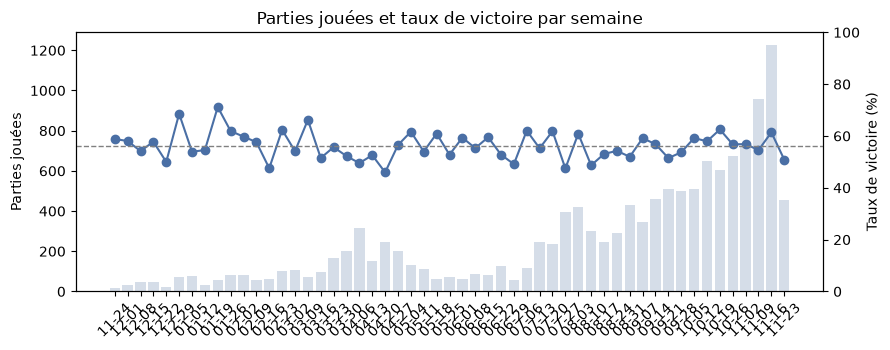

In [26]:
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(range(len(hebdo)), hebdo["parties"], color="#d5dde8")
ax.set_ylabel("Parties jouées")
ax2 = ax.twinx()
ax2.plot(range(len(hebdo)), 100 * hebdo["taux"], "o-", color="#4a6fa5")
ax2.axhline(100 * parties["win"].mean(), color="grey", ls="--", lw=1)
ax2.set_ylabel("Taux de victoire (%)"); ax2.set_ylim(0, 100)
ax.set_xticks(range(len(hebdo)), [str(d)[5:] for d in hebdo.index], rotation=45)
ax.set_title("Parties jouées et taux de victoire par semaine")
plt.tight_layout(); plt.show()

**Interprétation.** Le graphique ne montre **aucune tendance** : le taux de victoire oscille autour de sa moyenne de 56 % (ligne pointillée), avec des écarts plus forts au début, quand les semaines comptent peu de parties. La forte hausse du volume à partir d’août reflète la collecte (plus de comptes suivis, plafond de 300 parties atteint vite par les comptes actifs), pas une évolution du jeu.

## 3.7 Les séries

Une série garde le même joueur, la même famille et le même résultat sur des parties consécutives. Victoire, nulle, victoire donne deux séries de victoires de longueur 1 : la nulle coupe la série. `series_resultats()` calcule sur l’historique complet, puis on sélectionne une famille.

### 3.7.1 Séries maximales sur toute la base

Pour chaque famille, on relève la plus longue série de victoires, de défaites et de nulles. Une longue série attire l’œil, mais il faut la comparer à ce que le hasard produirait.

In [27]:
series, maxima = series_resultats(parties)
display(maxima.sort_values("max_serie_victoire", ascending=False).head(15))

result,opening_name,max_serie_victoire,max_serie_defaite,max_serie_nulle
35,English Opening,6,3,1
46,Hungarian Opening,5,3,1
101,Sicilian Defense,5,3,1
39,French Defense,4,2,2
48,Italian Game,3,3,1
54,King's Indian Defense,3,2,1
19,Caro-Kann Defense,3,2,1
98,Scandinavian Defense,3,2,1
90,Queen's Pawn Game,3,3,1
111,Van't Kruijs Opening,3,3,1


**Interprétation.** La plus longue série de victoires avec une même famille est de **6 parties** (English Opening), devant la Hungarian Opening et la Sicilienne (5). Aucune série de défaites ne dépasse 3, aucune série de nulles ne dépasse 2. Les séries sont courtes parce qu’on répète rarement la même famille deux fois de suite (11,8 % des enchaînements, section 4.1.3). Une série de 6 n’a rien d’exceptionnel sur 13 000 parties : avec un taux de victoire de 56 %, une série de 6 victoires démarre à chaque partie avec une probabilité de 0,56⁶ ≈ 3 %.

### 3.7.2 Deux graphiques pour résumer les exercices

`tracer_resultats()` dessine des graphiques sur les quatre familles les plus jouées et les enregistre dans `Resultats/`. Les deux blocs suivants affichent les résultats par famille, puis leur évolution mois par mois dans la fenêtre.

In [28]:
tracer_resultats(ouvertures, mensuel, maxima, cfg.RESULTS_DIR)
print("Graphiques enregistrés :", sorted(p.name for p in cfg.RESULTS_DIR.glob("*.png")))

Graphiques enregistrés : ['evolution_victoires.png', 'series_maximales.png', 'taux_ouvertures.png']


**Graphique 1 — Résultats par famille.** Les barres montrent, pour chaque famille, la part de victoires, de défaites et de nulles.

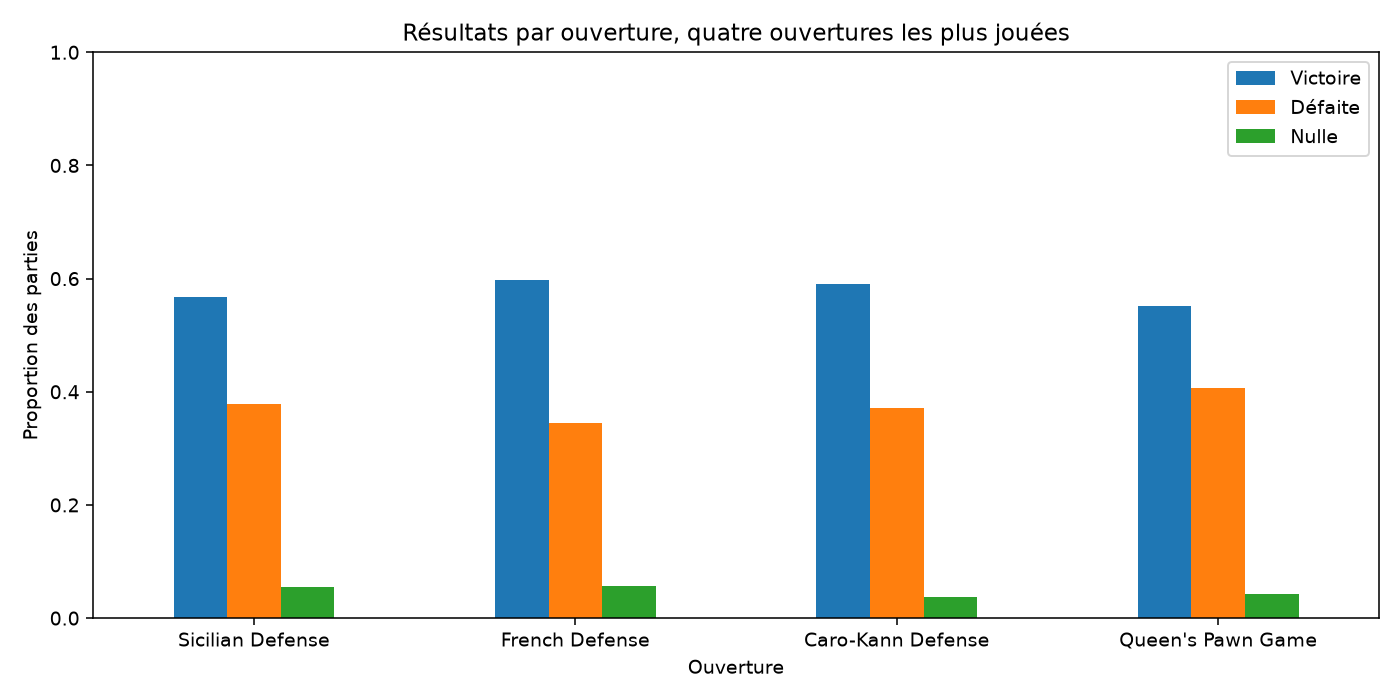

In [29]:
display(Image(filename=str(cfg.RESULTS_DIR / "taux_ouvertures.png")))

**Interprétation.** Les quatre familles les plus jouées ont des profils très proches : la Française gagne 59,8 %, la Caro-Kann 59,1 %, la Sicilienne 56,7 % et le Queen’s Pawn Game 55,2 %, avec 4 à 6 % de nulles. Les écarts entre familles, de l’ordre de 5 points, sont bien plus petits que les écarts entre joueurs vus en section 3.5.

**Graphique 2 — Évolution dans la fenêtre.** Les points donnent le taux de victoire mensuel de chaque famille.

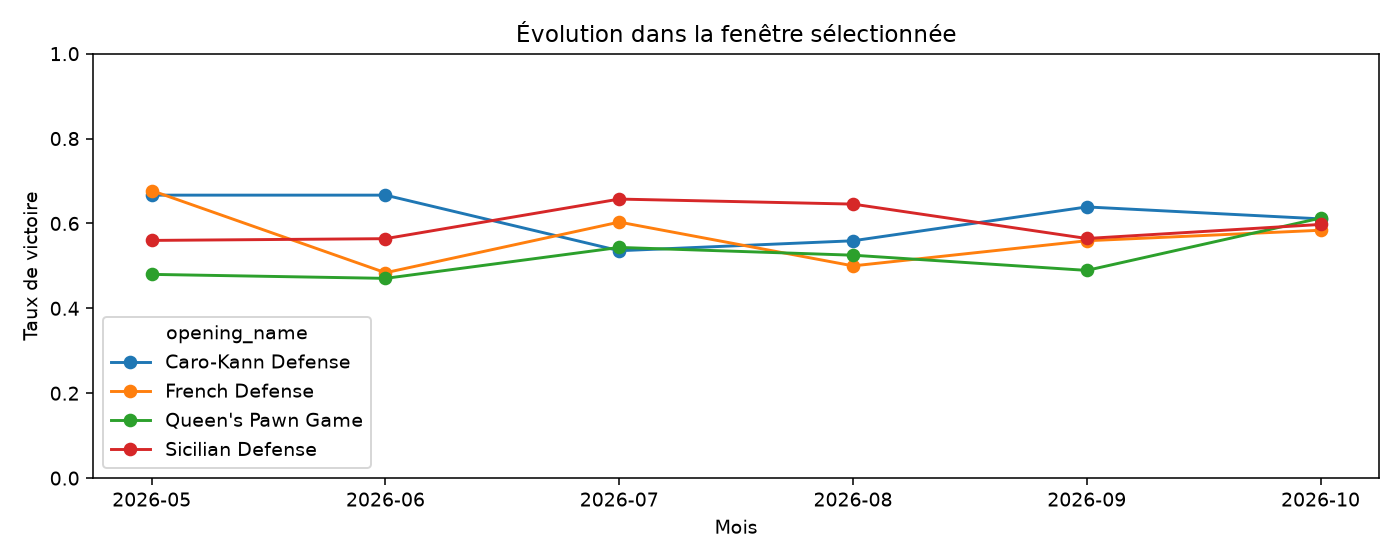

In [30]:
display(Image(filename=str(cfg.RESULTS_DIR / "evolution_victoires.png")))

**Interprétation.** Sur six mois, les taux mensuels des quatre familles restent entre environ 47 % et 68 %, sans tendance durable : la Française chute de 68 % en mai à 48 % en juin puis remonte, le Queen’s Pawn Game passe de 48 % à 61 % en octobre, la Sicilienne reste entre 56 % et 66 %. En octobre, les quatre familles se resserrent autour de 60 %, au moment où les effectifs sont les plus grands. Les variations de printemps reposent sur peu de parties : elles relèvent surtout du bruit et des changements de joueurs, ce que confirme la série hebdomadaire de la section 3.6.4.

# Partie 4 — Répéter l’ouverture après un succès

C’est la question centrale du projet. On prépare d’abord un nouveau jeu de données d’**enchaînements** (une partie et la suivante du même joueur), puis on compare la répétition et le changement de famille, d’abord sur tous les enchaînements, ensuite après une victoire seulement. On termine par des régressions, afin de vérifier si le lien résiste au niveau des joueurs.

## 4.1 Préparer les enchaînements de parties

Pour étudier l’effet de la répétition sur la partie suivante, il faut une ligne par partie avec les informations de la partie qui la suit chez le même joueur. On construit ce jeu de données en trois étapes.

### 4.1.1 Ajouter les informations de la partie suivante

On trie les parties de chaque joueur dans l’ordre chronologique, puis `shift(-1)` place sur chaque ligne les valeurs de la partie suivante du même joueur. Le suffixe `_suiv` désigne ces colonnes. Le `groupby("user_id")` évite de raccorder la dernière partie d’un joueur à la première du joueur suivant.

In [31]:
parties = parties.sort_values(["user_id", "date", "game_id"]).reset_index(drop=True)

g = parties.groupby("user_id", sort=False)
for col in ["game_id", "date", "opening_name", "color", "couleur", "win", "score",
            "opponent_id", "format_partie", "elo_diff", "_chronology_segment"]:
    parties[col + "_suiv"] = g[col].shift(-1)

print("Colonnes ajoutées :", [c for c in parties.columns if c.endswith("_suiv")])
print("Lignes avec une partie suivante :", int(parties["game_id_suiv"].notna().sum()), "sur", len(parties))

Colonnes ajoutées : ['game_id_suiv', 'date_suiv', 'opening_name_suiv', 'color_suiv', 'couleur_suiv', 'win_suiv', 'score_suiv', 'opponent_id_suiv', 'format_partie_suiv', 'elo_diff_suiv', '_chronology_segment_suiv']
Lignes avec une partie suivante : 13426 sur 13456


**Interprétation.** On a ajouté à chaque partie les informations de la partie suivante du même compte. **13 426 lignes sur 13 456** ont une partie suivante : les 30 restantes sont la dernière partie de chaque compte.

### 4.1.2 Ne garder que les vraies successions

On garde une ligne si la partie suivante existe, si elle est plus tardive, et si aucune partie n’a été retirée entre les deux par le nettoyage (même `_chronology_segment`). Comparer deux parties séparées par une partie retirée reviendrait à inventer une succession.

In [32]:
valide = (parties["game_id_suiv"].notna()
          & parties["date_suiv"].gt(parties["date"])
          & parties["_chronology_segment"].eq(parties["_chronology_segment_suiv"])
          & ~parties["_date_ambiguous"])
trans = parties.loc[valide].copy()
print("Enchaînements valides :", len(trans), "sur", len(parties) - parties.user_id.nunique(), "possibles")

Enchaînements valides : 13339 sur 13426 possibles


**Interprétation.** **13 339 enchaînements** sont valides. Les 87 écartés franchissent une rupture d’historique (section 2.3) : relier ces deux parties reviendrait à supposer qu’elles se suivent alors qu’il manque des parties entre elles.

### 4.1.3 Créer les indicateurs

On crée les variables qui serviront dans les parties 4 et 5 :

- `repete` = 1 si la partie suivante est de la **même famille** (vide si une des deux familles est inconnue) ;
- `meme_couleur` = 1 si le joueur garde **la même couleur** ;
- `meme_adversaire` = 1 si la partie suivante est **contre le même adversaire** ;
- les contrôles : `blancs_suiv`, l’écart Elo divisé par 100, et le délai entre les deux parties.

La famille d’ouverture dépend **des deux joueurs** : avec les Blancs on joue 1.e4, c’est l’adversaire qui choisit la Sicilienne. « Répéter son ouverture » a donc surtout un sens quand on garde la même couleur, ce que la partie 5 étudie.

In [33]:
connues = trans["opening_name"].notna() & trans["opening_name_suiv"].notna()
trans["repete"] = (trans["opening_name"] == trans["opening_name_suiv"]).where(connues).astype("float")
trans["meme_couleur"] = (trans["color"] == trans["color_suiv"]).astype(int)
trans["meme_adversaire"] = (trans["opponent_id"] == trans["opponent_id_suiv"]).astype(int)
trans["blancs_suiv"] = (trans["color_suiv"] == "white").astype(int)
trans["elo_suiv_100"] = trans["elo_diff_suiv"].astype(float) / 100
trans["win_suiv"] = trans["win_suiv"].astype(float)
trans["ecart_min"] = (trans["date_suiv"] - trans["date"]).dt.total_seconds() / 60

print("Familles connues des deux côtés :", int(connues.sum()))
print(f"Répète la famille : {trans.repete.mean():.1%} | garde la couleur : {trans.meme_couleur.mean():.1%} "
      f"| même adversaire : {trans.meme_adversaire.sum()} enchaînements")
print("Délai médian entre deux parties :", round(trans.ecart_min.median(), 1), "minutes")

Familles connues des deux côtés : 13072
Répète la famille : 11.8% | garde la couleur : 32.8% | même adversaire : 1062 enchaînements
Délai médian entre deux parties : 9.4 minutes


**Interprétation.** Sur 13 072 enchaînements dont les deux familles sont connues, le joueur **répète sa famille dans 11,8 % des cas** seulement. Il garde la même couleur dans 32,8 % des cas, car Lichess alterne en général les couleurs. 1 062 enchaînements se jouent contre le même adversaire, et le délai médian entre deux parties est de 9,4 minutes : la plupart des enchaînements se font dans la même séance de jeu.

## 4.2 Répéter ou changer de famille

On compare le taux de victoire de la partie suivante selon que le joueur répète ou change de famille, d’abord sur tous les enchaînements, puis selon le résultat de la partie précédente. Répéter une ouverture, c’est jouer une position qu’on connaît : on peut s’attendre à un avantage de familiarité. Mais un joueur peut aussi répéter par habitude, quelle que soit sa forme.

### 4.2.1 Garder les enchaînements dont les deux familles sont connues

On ajoute deux libellés lisibles : le choix (répète ou change) et le résultat de la partie précédente.

In [34]:
rep = trans.dropna(subset=["repete"]).copy()
rep["choix"] = rep["repete"].map({1.0: "Répète la famille", 0.0: "Change de famille"})
rep["partie_precedente"] = rep["win"].map({1: "après une victoire", 0: "après une nulle ou défaite"})
print("Enchaînements avec deux familles connues :", len(rep))

Enchaînements avec deux familles connues : 13072


### 4.2.2 Le taux de victoire selon le choix

On calcule le taux de victoire de la partie suivante quand on répète et quand on change de famille.

In [35]:
display(taux(rep, "choix").round(3))

,parties,victoires,taux,ic_bas,ic_haut
choix,,,,,
Change de famille,11534,6487,0.562,0.553,0.571
Répète la famille,1538,841,0.547,0.522,0.572


**Interprétation.** Le taux de victoire de la partie suivante est presque le même quand on répète sa famille (**54,7 %**, 1 538 enchaînements) et quand on en change (**56,2 %**, 11 534) ; les intervalles de confiance se chevauchent largement.

### 4.2.3 Le même taux selon la partie précédente

On sépare les enchaînements qui suivent une victoire de ceux qui suivent une nulle ou une défaite, afin de répondre à notre question de départ : répète-t-on davantage après une victoire, et cela aide-t-il ?

In [36]:
display(taux(rep, ["partie_precedente", "choix"]).round(3))

parties  victoires   taux  \
partie_precedente          choix                                          
après une nulle ou défaite Change de famille     5037       2551  0.506   
                           Répète la famille      681        320  0.470   
après une victoire         Change de famille     6497       3936  0.606   
                           Répète la famille      857        521  0.608   

                                              ic_bas  ic_haut  
partie_precedente          choix                               
après une nulle ou défaite Change de famille   0.493    0.520  
                           Répète la famille   0.432    0.507  
après une victoire         Change de famille   0.594    0.618  
                           Répète la famille   0.575    0.641

**Interprétation.** Le résultat de la partie précédente pèse beaucoup plus que le choix d’ouverture. Après une victoire, on gagne la suivante dans environ **61 %** des cas, qu’on répète (60,8 %) ou non (60,6 %). Après une nulle ou une défaite, on ne la gagne que dans environ 50 % des cas, avec un léger désavantage quand on répète (47,0 % contre 50,6 %), mais les intervalles se chevauchent.

### 4.2.4 Répète-t-on davantage après une victoire ?

C’est la question de départ du projet. On compare la part d’enchaînements où le joueur répète sa famille selon que la partie précédente a été gagnée ou non.

In [37]:
display(pd.crosstab(rep["partie_precedente"], rep["choix"], normalize="index").round(3))

choix,Change de famille,Répète la famille
partie_precedente,,
après une nulle ou défaite,0.881,0.119
après une victoire,0.883,0.117


**Interprétation.** C’est la réponse descriptive à la question de départ : on répète sa famille dans **11,7 %** des enchaînements après une victoire et dans **11,9 %** après une nulle ou une défaite. Les deux parts sont presque identiques : gagner ne pousse pas à rejouer la même ouverture.

On teste ensuite si la décision de répéter dépend du résultat de la partie précédente, avec un χ² d’indépendance.

In [38]:
t = chi2(rep, "win", y="repete"); tests.append({**t, "test": "répéter selon la partie précédente"}); print(t)

{'test': 'win', 'n': 13072, 'chi2': 0.203, 'ddl': 1, 'p': 0.652, 'V_Cramer': 0.004, 'attendu_min': 672.8}


**Interprétation.** Le χ² confirme l’absence de lien (χ² = 0,20, ddl = 1, **p = 0,65**, V de Cramér = 0,004). La décision de répéter sa famille ne dépend pas du résultat de la partie précédente : contrairement à l’intuition de Beth Harmon et à la règle « on garde ce qui gagne, on change ce qui perd », les joueurs de l’échantillon ne changent pas leur choix d’ouverture selon l’issue de la partie.

### 4.2.5 Répéter aide-t-il à gagner ?

On réalise trois χ² entre la répétition et la victoire suivante : sur tous les enchaînements, après une victoire, après une non-victoire.

In [39]:
for nom, sous in [("répétition (tous)", rep), ("répétition après victoire", rep[rep.win == 1]),
                  ("répétition après non-victoire", rep[rep.win == 0])]:
    t = chi2(sous, "repete"); tests.append({**t, "test": nom}); print(nom, ":", t)

répétition (tous) : {'test': 'repete', 'n': 13072, 'chi2': 1.342, 'ddl': 1, 'p': 0.2466, 'V_Cramer': 0.01, 'attendu_min': 675.8}


répétition après victoire : {'test': 'repete', 'n': 7354, 'chi2': 0.014, 'ddl': 1, 'p': 0.9051, 'V_Cramer': 0.001, 'attendu_min': 337.6}
répétition après non-victoire : {'test': 'repete', 'n': 5718, 'chi2': 3.207, 'ddl': 1, 'p': 0.0733, 'V_Cramer': 0.024, 'attendu_min': 339.1}


**Interprétation.** Aucun des trois tests n’est significatif au seuil de 5 % : sur tous les enchaînements (p = 0,25), après une victoire (p = 0,91) et après une non-victoire (p = 0,073). Le seul écart notable, 47,0 % contre 50,6 % après une non-victoire, reste à la limite et ne résistera pas à la correction pour tests multiples (section 5.6).

## 4.3 Après une victoire : le test du χ² en détail

On se concentre maintenant sur l’après-victoire, en détaillant chaque étape du test avec les fonctions du projet (fichier `Analyse_repetition_ouverture.py`).

### 4.3.1 Construire les transitions avec les fonctions du projet

`preparer_cadres()` refait la même opération que la section 4.1, puis propose trois définitions de la partie suivante (« cadres »), comparées en section 4.4. On commence par le cadre immédiat. Retrouver le même nombre de transitions qu’en 4.1 est un contrôle de cohérence.

In [40]:
cadres = preparer_cadres(parties)
transitions = cadres["immediat"]
print("Transitions immédiates exploitables :", len(transitions))

Transitions immédiates exploitables : 13339


**Interprétation.** `preparer_cadres()` construit **13 339 transitions immédiates**. C’est exactement le nombre d’enchaînements de la section 4.1.2 : les deux constructions concordent.

### 4.3.2 Garder les transitions qui suivent une victoire

`taux_apres_victoire()` ne garde que les transitions dont la première partie est gagnée et dont les deux familles sont connues, puis calcule le taux de victoire suivante selon que le joueur répète (`repeat_opening` = 1) ou change (0).

In [41]:
apres_victoire, taux_apres = taux_apres_victoire(transitions)  # taux_apres : ne pas écraser la fonction taux()
print("Après victoire avec deux ouvertures connues :", len(apres_victoire))
display(apres_victoire[["user_id", "game_id", "opening_name", "opening_name_next", "repeat_opening", "win_next"]].head(8))

Après victoire avec deux ouvertures connues : 7354


,user_id,game_id,opening_name,opening_name_next,repeat_opening,win_next
0,bcow,hIraugYt,Hungarian Opening,Van't Kruijs Opening,0.0,0.0
3,bcow,je61GnLN,Sicilian Defense,Hungarian Opening,0.0,1.0
4,bcow,44Brcqg1,Hungarian Opening,Sicilian Defense,0.0,0.0
6,bcow,Jq9B0A4E,Hungarian Opening,Sicilian Defense,0.0,1.0
7,bcow,jqglO88c,Sicilian Defense,Sicilian Defense,1.0,1.0
8,bcow,qXaEtzHc,Sicilian Defense,Caro-Kann Defense,0.0,1.0
9,bcow,4JNOS1mZ,Caro-Kann Defense,Nimzo-Larsen Attack,0.0,1.0
10,bcow,A3mNW6yg,Nimzo-Larsen Attack,Mieses Opening,0.0,1.0


**Interprétation.** On garde **7 354 transitions** qui suivent une victoire et dont les deux familles sont connues. Les premières lignes montrent les colonnes clés : l’ouverture jouée, celle de la partie suivante, l’indicateur de répétition et le résultat suivant.

### 4.3.3 Comparer les taux avant le test

On lit l’écart et les effectifs avant la p-value : un test sans ordre de grandeur ne dit rien de l’importance de l’effet.

In [42]:
display(taux_apres.round(4))

,n,joueurs,victoires_suivantes,taux_victoire
repeat_opening,,,,
0.0,6497,30,3936.0,0.6058
1.0,857,26,521.0,0.6079


**Interprétation.** Après une victoire, on gagne la partie suivante dans **60,6 %** des cas quand on change de famille (6 497 transitions, 30 joueurs) et dans **60,8 %** quand on la répète (857 transitions, 26 joueurs). L’écart, **+0,2 point**, est négligeable.

### 4.3.4 Le tableau observé

`tester_table()` construit le tableau croisé : répète ou change, puis gagne ou ne gagne pas (« ne gagne pas » regroupe défaites et nulles). Sous l’hypothèse H₀, répéter et gagner la partie suivante sont indépendants.

In [43]:
bilan_test, observes, attendus = tester_table(apres_victoire)
display(observes)

win_next,0.0,1.0
repeat_opening,,
0.0,2561,3936
1.0,336,521


**Interprétation.** Le tableau observé contient les quatre cases du test : 336 répétitions suivies d’une non-victoire, 521 suivies d’une victoire, et 2 561 et 3 936 pour les changements de famille.

### 4.3.5 Les effectifs attendus sous H₀

Pour chaque case, l’effectif attendu vaut total de sa ligne × total de sa colonne ÷ total général. Le test est fiable si chaque effectif attendu dépasse 5.

In [44]:
display(attendus.round(2))

win_next,0.0,1.0
repeat_opening,,
0.0,2559.4,3937.6
1.0,337.6,519.4


**Interprétation.** Sans lien entre répétition et victoire, on attendrait 337,6 et 519,4 dans la ligne « répète » : c’est presque exactement ce qu’on observe (336 et 521). Le plus petit effectif attendu, 337,6, dépasse largement 5 : le χ² est fiable.

### 4.3.6 Lire le χ²

La statistique somme $(O-E)^2/E$ sur les quatre cases ; un tableau 2 × 2 a un degré de liberté. Le V de Cramér mesure la force du lien, de 0 à 1.

In [45]:
print("χ² =", round(bilan_test["chi2"], 3), "| ddl =", bilan_test["ddl"], "| p exploratoire =", round(bilan_test["p_chi2"], 4))
print("Minimum attendu :", round(bilan_test["min_expected"], 2), "| V de Cramér :", round(bilan_test["cramer_v"], 4))

χ² = 0.014 | ddl = 1 | p exploratoire = 0.9051
Minimum attendu : 337.6 | V de Cramér : 0.0014


**Interprétation.** Le χ² vaut **0,014** pour 1 degré de liberté (**p = 0,91**), avec un V de Cramér de 0,001. Après une victoire, répéter sa famille n’est associé à aucune différence de taux de victoire.

## 4.4 Trois définitions de la partie suivante

On ne peut rejouer sa Sicilienne qu’avec les Noirs : la « partie suivante » peut donc se définir de trois façons. `tests_repetition()` refait le test dans les trois cadres et corrige les p-values par la méthode de Holm, car faire trois tests augmente le risque de faux positif.

In [46]:
tests_cadres, taux_par_cadre = tests_repetition(parties, cfg.RESULTS_DIR)
display(tests_cadres[["cadre", "n", "chi2", "ddl", "min_expected", "cramer_v", "p_chi2_holm", "p_fisher_holm"]].round(4))

,cadre,n,chi2,ddl,min_expected,cramer_v,p_chi2_holm,p_fisher_holm
0,immediat,7354,0.0142,1,337.6025,0.0014,1.0,1.0
1,immediat_meme_couleur,2365,0.6692,1,222.7281,0.0168,1.0,1.0
2,prochaine_meme_couleur,7292,0.6863,1,749.1587,0.0097,1.0,1.0


**Interprétation.** Quelle que soit la définition de la partie suivante (immédiate, immédiate de même couleur, prochaine partie de même couleur), aucun test n’est significatif : toutes les p-values corrigées par Holm valent 1, et les V de Cramér restent inférieurs à 0,02.

On affiche ensuite, cadre par cadre, le taux de victoire suivante en répétant et en changeant.

In [47]:
display(pd.concat({nom: tableau for nom, tableau in taux_par_cadre.items()}).round(4))

n  joueurs  victoires_suivantes  \
                       repeat_opening                                       
immediat               0.0             6497       30               3936.0   
                       1.0              857       26                521.0   
immediat_meme_couleur  0.0             1807       28               1094.0   
                       1.0              558       25                327.0   
prochaine_meme_couleur 0.0             5405       28               3244.0   
                       1.0             1887       27               1153.0   

                                       taux_victoire  
                       repeat_opening                 
immediat               0.0                    0.6058  
                       1.0                    0.6079  
immediat_meme_couleur  0.0                    0.6054  
                       1.0                    0.5860  
prochaine_meme_couleur 0.0                    0.6002  
                       1.0                    0.6110

**Interprétation.** Dans les trois cadres, les écarts entre répéter et changer restent inférieurs à 2 points et ne vont pas tous dans le même sens : +0,2 point dans le cadre immédiat, −1,9 point (58,6 % contre 60,5 %) quand la partie suivante garde la couleur, +1,1 point pour la prochaine partie de même couleur. C’est la signature d’un effet nul.

## 4.5 Fisher et bootstrap

### 4.5.1 Le test exact de Fisher

On lit le test de Fisher calculé par `tester_table()` sur le même tableau 2 × 2. Il calcule une probabilité exacte, sans approximation, et reste valable avec de petits effectifs. Son odds ratio compare les « cotes » de victoire des deux groupes.

In [48]:
print("Odds ratio :", round(bilan_test["odds_ratio_fisher"], 3))
print("Valeur p exploratoire :", round(bilan_test["p_fisher"], 4))
print("Nombre de lignes du tableau :", bilan_test["n"])

Odds ratio : 1.009
Valeur p exploratoire : 0.9112
Nombre de lignes du tableau : 7354


**Interprétation.** Le test exact de Fisher donne un odds ratio de **1,01** (p = 0,91) : les chances de gagner sont les mêmes après une répétition et après un changement. Il confirme le χ².

### 4.5.2 Rééchantillonner les joueurs

Le χ² et Fisher traitent les transitions comme indépendantes, alors que plusieurs viennent du même joueur. `bootstrap_joueurs()` tire 1 000 fois des joueurs avec remise, en gardant ensemble toutes leurs transitions, et recalcule à chaque fois l’écart répéter − changer. Il n’est calculé qu’à partir de 20 comptes.

In [49]:
incertitude = bootstrap_joueurs(apres_victoire, simulations=1000, seed=cfg.RANDOM_SEED)
print("Comptes :", incertitude["joueurs"])
print("Écart répéter − changer :", round(100 * incertitude["difference"], 2), "points de pourcentage")
print("Intervalle à 95 % :", 100 * incertitude["ci_low"], "à", 100 * incertitude["ci_high"], "points")

Comptes : 30
Écart répéter − changer : 0.21 points de pourcentage
Intervalle à 95 % : -4.645157645533477 à 4.8860523254442 points


**Interprétation.** Avec 30 comptes, le bootstrap par joueur est désormais possible. L’écart répéter − changer vaut **+0,2 point**, avec un intervalle à 95 % de **−4,6 à +4,9 points** : il contient zéro. Sa largeur, près de 10 points, montre que l’incertitude réelle vient des différences entre joueurs, bien plus que le χ² ne le laisse penser.

## 4.6 Les régressions sur la répétition après victoire

On estime trois **modèles de probabilité linéaire** (une régression par issue : victoire, défaite, nulle de la partie suivante) avec la répétition, la victoire courante, leur interaction et trois contrôles : l’écart Elo par 100 points, la couleur et la cadence. Les erreurs-types sont groupées par joueur. On vérifie ainsi si le lien observé résiste au niveau des joueurs.

### 4.6.1 Préparer l’échantillon des modèles

`preparer_regressions()` reprend les transitions et ajoute l’écart Elo divisé par 100.

In [50]:
base_modeles = preparer_regressions(parties)
print("Transitions avant exclusion des contrôles manquants :", len(base_modeles))

Transitions avant exclusion des contrôles manquants : 13339


**Interprétation.** La base des régressions part des **13 339 transitions** valides, comme dans les sections précédentes.

### 4.6.2 Repérer les valeurs manquantes

Une ligne incomplète sort des trois modèles à la fois : on compte les valeurs manquantes de chaque variable.

In [51]:
variables_modeles = ["repeat_opening", "win", "win_next", "loss_next", "draw_next", "elo_diff_100", "is_white_next", "format_partie_next"]
display(base_modeles[variables_modeles].isna().sum().to_frame("manquantes"))

,manquantes
repeat_opening,267
win,0
win_next,0
loss_next,0
draw_next,0
elo_diff_100,0
is_white_next,0
format_partie_next,0


**Interprétation.** Seule la répétition a des valeurs manquantes (267 transitions dont l’une des deux familles est inconnue). Les modèles portent donc sur 13 339 − 267 = **13 072 transitions**.

### 4.6.3 Estimer les trois modèles

`regressions_lineaires()` estime les trois modèles sur le même échantillon et affiche leurs diagnostics : nombre d’observations, de comptes, R², prédictions hors de [0 ; 1].

In [52]:
if cfg.RUN_REGRESSIONS:
    modeles, coefficients = regressions_lineaires(parties)
else:
    modeles, coefficients = pd.DataFrame(), pd.DataFrame()
display(modeles[["modele", "n_transitions", "n_joueurs", "r2", "inferer", "predictions_hors_0_1"]])

,modele,n_transitions,n_joueurs,r2,inferer,predictions_hors_0_1
0,victoire,13072,30,0.122800,True,438
1,defaite,13072,30,0.116756,True,540
2,nulle,13072,30,0.004164,True,9


**Interprétation.** Les trois modèles portent sur **13 072 transitions de 30 joueurs**. Le R² atteint 0,12 pour la victoire et la défaite, presque rien pour la nulle (0,004), qui reste imprévisible. Le modèle linéaire prédit des probabilités hors de [0 ; 1] dans 3 à 4 % des cas (438 et 540) : c’est sa limite connue, d’où la vérification par un logit en section 5.3.4.

### 4.6.4 Lire les coefficients

On affiche les coefficients centraux en points de probabilité. `repeat_opening` donne l’écart répéter − changer après une défaite ou une nulle ; `repeat_opening:win` dit de combien cet écart change après une victoire.

In [53]:
centrales = coefficients.variable.isin(["repeat_opening", "win", "repeat_opening:win", "elo_diff_100", "is_white_next"])
display(coefficients.loc[centrales, ["modele", "variable", "effet_points", "se_groupee", "p_groupee"]].round(3))

,modele,variable,effet_points,se_groupee,p_groupee
4,victoire,repeat_opening,-4.283,0.019,0.036
5,victoire,win,2.553,0.009,0.008
6,victoire,repeat_opening:win,3.816,0.025,0.134
7,victoire,elo_diff_100,6.779,0.006,0.000
8,victoire,is_white_next,3.359,0.007,0.000
13,defaite,repeat_opening,4.320,0.019,0.029
14,defaite,win,-2.716,0.009,0.005
15,defaite,repeat_opening:win,-5.128,0.024,0.042
16,defaite,elo_diff_100,-6.478,0.007,0.000
17,defaite,is_white_next,-2.218,0.007,0.006


**Interprétation.** À écart Elo, couleur et cadence égaux, **100 points d’Elo** valent +6,8 points de probabilité de victoire et jouer avec les Blancs +3,4 points : ce sont les deux effets les plus nets. Gagner la partie précédente ajoute +2,6 points (p = 0,008). Répéter sa famille **après une non-victoire** est associé à −4,3 points de victoire (p = 0,036) et +4,3 points de défaite (p = 0,029). Ce résultat est fragile : avec seulement deux coefficients corrigés par Holm, sa p-value dépasserait déjà 0,05 (0,036 × 2 = 0,072). L’interaction avec la victoire précédente (+3,8 points, p = 0,13) n’est pas significative pour la victoire.

### 4.6.5 L’écart ajusté après une victoire

Après une victoire, les deux termes de répétition s’additionnent. On calcule cette somme pour chaque issue : c’est la réponse directe à la question de la partie, à Elo, couleur et cadence égaux.

In [54]:
termes = ["repeat_opening", "repeat_opening:win"]
effets = coefficients.loc[coefficients.variable.isin(termes)].pivot(index="modele", columns="variable", values="effet_points")
after_win = effets.reindex(columns=termes).sum(axis=1, min_count=2)
for resultat, points in after_win.items():
    print(f"{resultat} : {points:+.3f} points après une victoire")

defaite : -0.808 points après une victoire
nulle : +1.276 points après une victoire
victoire : -0.468 points après une victoire


**Interprétation.** **Après une victoire**, l’effet total de la répétition (β₁ + β₃) vaut −0,5 point sur la probabilité de gagner, −0,8 point sur celle de perdre et +1,3 point sur celle de faire nulle. À niveau égal, répéter son ouverture après un succès ne change donc rien aux chances de la partie suivante.

# Partie 5 — Les autres causes possibles

La partie 4 montre que répéter sa famille après une victoire ne change presque rien, une fois le niveau pris en compte. On cherche maintenant ce qui, autour de la partie, peut influer sur la victoire : la couleur, la combinaison de la famille et de la couleur, la fatigue au fil d’une session, et l’adversaire.

## 5.1 Garder la même couleur

Sur Lichess, la couleur est attribuée par le serveur ; lors d’une revanche contre le même adversaire, elle alterne. Garder la couleur peut donc signaler un autre contexte de jeu. Comme les Blancs ont l’avantage du premier coup (section 3.4), il faut séparer « garder la couleur » de « jouer les Blancs ».

### 5.1.1 Le taux de victoire selon le passage de couleur

On croise la couleur de la partie et celle de la suivante : Blancs → Blancs, Noirs → Noirs, Blancs → Noirs, Noirs → Blancs.

In [55]:
trans["passage"] = trans["couleur"] + " → " + trans["couleur_suiv"]
display(taux(trans, ["meme_couleur", "passage"]).round(3))

parties  victoires   taux  ic_bas  ic_haut
meme_couleur passage                                                    
0            Blancs → Noirs      4486       2446  0.545   0.531    0.560
             Noirs → Blancs      4475       2607  0.583   0.568    0.597
1            Blancs → Blancs     2214       1247  0.563   0.543    0.584
             Noirs → Noirs       2164       1185  0.548   0.527    0.569

**Interprétation.** La couleur de la partie suivante compte plus que le fait de la garder. Passer des Noirs aux Blancs est l’enchaînement le plus favorable (**58,3 %**), passer des Blancs aux Noirs le moins favorable (54,5 %). Garder la même couleur donne des taux intermédiaires : 56,3 % pour Blancs → Blancs, 54,8 % pour Noirs → Noirs.

### 5.1.2 Tester l’effet de garder la couleur

On réalise un χ² sur tous les enchaînements, puis un χ² séparé selon la couleur de la partie suivante.

In [56]:
t = chi2(trans, "meme_couleur"); tests.append({**t, "test": "même couleur"}); print("Tous :", t)
for c in ["Blancs", "Noirs"]:
    t = chi2(trans[trans.couleur_suiv == c], "meme_couleur")
    tests.append({**t, "test": f"même couleur, partie suivante avec les {c}"}); print(c, ":", t)

Tous : {'test': 'meme_couleur', 'n': 13339, 'chi2': 0.839, 'ddl': 1, 'p': 0.3596, 'V_Cramer': 0.008, 'attendu_min': 1921.3}
Blancs : {'test': 'meme_couleur', 'n': 6689, 'chi2': 2.268, 'ddl': 1, 'p': 0.1321, 'V_Cramer': 0.018, 'attendu_min': 938.4}
Noirs : {'test': 'meme_couleur', 'n': 6650, 'chi2': 0.032, 'ddl': 1, 'p': 0.8572, 'V_Cramer': 0.002, 'attendu_min': 982.4}


**Interprétation.** Garder la couleur n’a pas d’effet significatif, ni sur tous les enchaînements (p = 0,36), ni quand la partie suivante se joue avec les Blancs (p = 0,13) ou avec les Noirs (p = 0,86). L’écart vu au tableau précédent tient à la couleur jouée ensuite, déjà étudiée en section 3.4.

## 5.2 Même famille et même couleur

C’est la définition la plus juste de « rejouer son ouverture » : la même famille **avec la même couleur**, donc vraisemblablement le même répertoire choisi par le joueur. Si un avantage de familiarité existe, c’est dans cette case qu’il doit apparaître.

### 5.2.1 Les quatre situations

On croise les deux décisions (répéter ou non la famille, garder ou non la couleur) et on calcule le taux de victoire de la partie suivante dans chacune des quatre situations.

In [57]:
rep["situation"] = (rep["repete"].map({1.0: "même famille", 0.0: "autre famille"}) + " / "
                    + rep["meme_couleur"].map({1: "même couleur", 0: "autre couleur"}))
quatre = taux(rep, "situation").sort_values("taux", ascending=False)
display(quatre.round(3))

,parties,victoires,taux,ic_bas,ic_haut
situation,,,,,
même famille / autre couleur,518,299,0.577,0.535,0.620
autre famille / même couleur,3231,1820,0.563,0.546,0.580
autre famille / autre couleur,8303,4667,0.562,0.551,0.573
même famille / même couleur,1020,542,0.531,0.501,0.562


**Interprétation.** Les quatre situations sont proches : de **53,1 %** (même famille et même couleur, 1 020 enchaînements) à **57,7 %** (même famille, autre couleur, 518 enchaînements), autour d’une moyenne de 56 %. Rejouer exactement son répertoire, même famille et même couleur, est même la situation la moins favorable ici, à l’inverse de ce que suggérait la collecte de test.

### 5.2.2 Tester les quatre situations

On réalise un χ² sur le tableau 4 × 2, puis un χ² répéter / changer limité aux enchaînements où la couleur est gardée.

In [58]:
t = chi2(rep, "situation"); tests.append({**t, "test": "famille × couleur (4 situations)"}); print("Quatre situations :", t)
t = chi2(rep[rep.meme_couleur == 1], "repete"); tests.append({**t, "test": "répétition, à couleur gardée"}); print("À couleur gardée :", t)

Quatre situations : {'test': 'situation', 'n': 13072, 'chi2': 4.288, 'ddl': 3, 'p': 0.232, 'V_Cramer': 0.018, 'attendu_min': 227.6}
À couleur gardée : {'test': 'repete', 'n': 4251, 'chi2': 3.199, 'ddl': 1, 'p': 0.0737, 'V_Cramer': 0.027, 'attendu_min': 453.3}


**Interprétation.** Les quatre situations ne diffèrent pas significativement (p = 0,23). À couleur gardée, répéter sa famille fait passer de 56,3 % à 53,1 % (p = 0,074) : l’écart reste à la limite du seuil et devra être vérifié à niveau égal.

### 5.2.3 Visualiser les quatre situations

On représente une barre par situation, avec son intervalle de confiance ; la ligne pointillée marque le taux moyen.

In [59]:
q = quatre.sort_values("taux")
ax = q.plot.barh(y="taux", xerr=[q["taux"] - q["ic_bas"], q["ic_haut"] - q["taux"]],
                 legend=False, figsize=(8, 3), color="#4a6fa5")
ax.axvline(rep["win_suiv"].mean(), color="grey", ls="--", lw=1)
ax.set(xlabel="Taux de victoire de la partie suivante (IC 95 %)", ylabel="", title="Quatre façons d’enchaîner deux parties")
plt.tight_layout(); plt.show()

**Interprétation.** Les intervalles de confiance des quatre situations se chevauchent tous et entourent la moyenne (ligne pointillée). Aucune combinaison de famille et de couleur ne se détache nettement.

## 5.3 Une régression qui réunit tout

Les comparaisons précédentes mélangent des joueurs différents : un joueur fort gagne souvent **et** peut répéter souvent, sans que la répétition y soit pour quelque chose. On estime donc la probabilité de gagner la partie suivante avec **toutes les variables à la fois** :

$$\Pr(\text{victoire}_{t+1}) = \alpha_{\text{joueur}} + \beta_1\,\text{répète} + \beta_2\,\text{même couleur} + \beta_3\,(\text{répète}\times\text{même couleur}) + \beta_4\,\text{victoire}_t + \beta_5\,\text{Blancs}_{t+1} + \beta_6\,\frac{\Delta \text{Elo}_{t+1}}{100} + \gamma_{\text{cadence}} + \varepsilon$$

| Modèle | Variables | Ce qu’il teste |
|---|---|---|
| M1 | répète, même couleur, interaction | Les effets bruts des deux décisions |
| M2 | M1 + victoire précédente, Blancs, écart Elo, cadence | Les mêmes effets **à niveau, couleur et cadence égaux** |
| M3 | M2 + un effet fixe par joueur (`C(user_id)`) | Les mêmes effets **à l’intérieur d’un même joueur** |

Les coefficients se lisent en **points de probabilité**. Les erreurs-types sont groupées par joueur ; avec 17 joueurs, elles restent approximatives.

### 5.3.1 Estimer les trois modèles

On retire les enchaînements sans écart Elo ou sans cadence, puis on estime M1, M2 et M3 et on affiche leurs coefficients côte à côte, en points de probabilité.

In [60]:
donnees = rep.dropna(subset=["elo_suiv_100", "format_partie_suiv"]).copy()
donnees["format_suiv"] = donnees["format_partie_suiv"].astype(str)
formules = {
    "M1 brut": "win_suiv ~ repete * meme_couleur",
    "M2 contrôles": "win_suiv ~ repete * meme_couleur + win + blancs_suiv + elo_suiv_100 + C(format_suiv)",
    "M3 effet fixe joueur": "win_suiv ~ repete * meme_couleur + win + blancs_suiv + elo_suiv_100 + C(format_suiv) + C(user_id)",
}
lignes, mod = [], {}
for nom, f in formules.items():
    m = smf.ols(f, data=donnees).fit(cov_type="cluster", cov_kwds={"groups": donnees["user_id"]})
    mod[nom] = m
    for v in ["repete", "meme_couleur", "repete:meme_couleur", "win", "blancs_suiv", "elo_suiv_100"]:
        if v in m.params:
            bas, haut = m.conf_int().loc[v]
            lignes.append({"modèle": nom, "variable": v, "effet (points)": 100 * m.params[v],
                           "IC bas": 100 * bas, "IC haut": 100 * haut, "p": m.pvalues[v]})
coef = pd.DataFrame(lignes)
display(coef.pivot(index="variable", columns="modèle", values="effet (points)").round(2))

modèle,M1 brut,M2 contrôles,M3 effet fixe joueur
variable,,,
blancs_suiv,NaN,3.38,3.30
elo_suiv_100,NaN,6.78,6.34
meme_couleur,0.12,0.20,0.23
repete,1.51,-0.84,-2.16
repete:meme_couleur,-4.71,-2.10,-1.53
win,NaN,3.00,1.85


**Interprétation.** Les coefficients bougent quand on ajoute les contrôles. Brut (M1), répéter vaut +1,5 point et l’interaction répète × même couleur −4,7 points. À niveau égal (M2), puis à l’intérieur de chaque joueur (M3), l’effet de la répétition devient négatif (−0,8 puis −2,2) et l’interaction se réduit (−2,1 puis −1,5). Les effets du classement (+6,3 à +6,8 points pour 100 Elo) et des Blancs (+3,3 points) restent stables : ce sont eux qui expliquent le résultat.

### 5.3.2 Le détail du modèle le plus exigeant (M3)

On affiche les coefficients de M3 avec leur intervalle de confiance à 95 % et leur p-value.

In [61]:
print("Détail du modèle M3 (effets en points de probabilité, IC 95 %) — n =", int(mod["M3 effet fixe joueur"].nobs))
display(coef[coef["modèle"] == "M3 effet fixe joueur"].drop(columns="modèle").round(3))

Détail du modèle M3 (effets en points de probabilité, IC 95 %) — n = 13072


,variable,effet (points),IC bas,IC haut,p
9,repete,-2.157,-8.259,3.944,0.488
10,meme_couleur,0.231,-1.736,2.197,0.818
11,repete:meme_couleur,-1.526,-9.072,6.019,0.692
12,win,1.850,0.048,3.653,0.044
13,blancs_suiv,3.300,1.930,4.669,0.000
14,elo_suiv_100,6.338,5.168,7.508,0.000


**Interprétation.** Dans M3, aucun des termes liés à l’ouverture n’est significatif : répéter vaut −2,2 points [−8,3 ; +3,9], l’interaction −1,5 point [−9,1 ; +6,0], garder la couleur +0,2 point. Les intervalles sont larges et contiennent tous zéro. Seuls le classement (+6,3 points pour 100 Elo), les Blancs (+3,3) et, de justesse, la victoire précédente (+1,9 point, p = 0,044) restent significatifs.

### 5.3.3 La qualité des modèles et l’effet total de répéter à couleur gardée

On compare le R² des trois modèles, puis on calcule dans M3 l’effet total de répéter quand on garde la couleur (β1 + β3) et sa p-value.

In [62]:
print("R² :", {k: round(float(m.rsquared), 3) for k, m in mod.items()})
# Effet total de répéter quand on garde la couleur (β1 + β3) dans M3.
m3 = mod["M3 effet fixe joueur"]
total_m3 = m3.t_test("repete + repete:meme_couleur = 0")
print(f"Répéter à couleur gardée (β1 + β3) : {100 * total_m3.effect.item():+.1f} points, p = {total_m3.pvalue.item():.3f}")

R² : {'M1 brut': 0.0, 'M2 contrôles': 0.123, 'M3 effet fixe joueur': 0.131}
Répéter à couleur gardée (β1 + β3) : -3.7 points, p = 0.034


**Interprétation.** Le R² passe de 0 (M1) à 0,123 (M2) puis 0,131 (M3) : presque tout le pouvoir explicatif vient des contrôles, surtout de l’Elo, et non des choix d’ouverture. Répéter sa famille en gardant la couleur (β₁ + β₃) est associé à **−3,7 points** (p = 0,034). Ce résultat est fragile : il ne survivrait pas à une correction pour tests multiples, et il est de signe opposé au +6,3 points obtenu sur la collecte de test. Un effet qui change de signe d’un échantillon à l’autre relève du bruit.

### 5.3.4 Vérifier avec une régression logistique

On réestime M2 avec une régression logistique et on calcule les effets marginaux moyens, en points de probabilité.

Le modèle linéaire peut prédire des probabilités hors de [0 ; 1]. Si la logistique donne les mêmes conclusions, elles ne tiennent pas au choix du modèle.

In [63]:
logit = smf.logit(formules["M2 contrôles"], data=donnees).fit(disp=False, cov_type="cluster",
                                                                cov_kwds={"groups": donnees["user_id"]})
effets_logit = logit.get_margeff(at="overall").summary_frame()
effets_logit = (100 * effets_logit[["dy/dx", "Conf. Int. Low", "Cont. Int. Hi."]]).join(effets_logit[["Pr(>|z|)"]])
effets_logit.columns = ["effet (points)", "IC bas", "IC haut", "p"]
display(effets_logit.loc[[i for i in effets_logit.index if not i.startswith("C(")]].round(3))

,effet (points),IC bas,IC haut,p
repete,-2.130,-7.491,3.231,0.436
meme_couleur,0.313,-1.544,2.170,0.741
repete:meme_couleur,-0.795,-7.297,5.707,0.811
win,2.158,0.401,3.915,0.016
blancs_suiv,3.334,1.948,4.720,0.000
elo_suiv_100,9.902,9.020,10.784,0.000


**Interprétation.** Le logit donne les mêmes conclusions que le modèle linéaire : répéter (−2,1 points, p = 0,44), garder la couleur et leur interaction ne sont pas significatifs, alors que l’Elo (+9,9 points pour 100 Elo), les Blancs (+3,3) et la victoire précédente (+2,2, p = 0,016) le sont. Les limites du modèle linéaire (prédictions hors de [0 ; 1]) ne changent donc pas le résultat.

## 5.4 La session et la main chaude

On joue souvent plusieurs parties d’affilée. La fatigue, l’échauffement ou l’énervement après une défaite peuvent faire varier les résultats au fil d’une session, et les victoires peuvent sembler s’enchaîner.

### 5.4.1 Découper l’historique en sessions

Deux parties d’un même joueur séparées de plus de 30 minutes appartiennent à deux sessions différentes. On numérote les sessions, puis le rang de chaque partie dans sa session.

In [64]:
ecart = parties.groupby("user_id")["date"].diff().dt.total_seconds().div(60)
parties["nouvelle_session"] = ecart.isna() | (ecart > 30)
parties["session"] = parties.groupby("user_id")["nouvelle_session"].cumsum()
parties["rang"] = parties.groupby(["user_id", "session"]).cumcount() + 1
parties["rang_session"] = pd.cut(parties["rang"], [0, 1, 2, 3, 5, 10, 1000],
                                 labels=["1re", "2e", "3e", "4e-5e", "6e-10e", "11e et +"])
tailles = parties.groupby(["user_id", "session"]).size()
print(f"Sessions : {len(tailles)} | parties par session : médiane {tailles.median():.0f}, "
      f"moyenne {tailles.mean():.1f}, maximum {tailles.max()}")

Sessions : 4548 | parties par session : médiane 1, moyenne 3.0, maximum 123


**Interprétation.** En coupant l’historique dès que deux parties sont séparées de plus de 30 minutes, on obtient **4 548 sessions**. La moitié ne contiennent qu’une partie (médiane 1), la moyenne est de 3 parties et la plus longue en compte 123.

### 5.4.2 Le taux de victoire selon le rang dans la session

On calcule le taux de victoire de la 1re, 2e, 3e… partie d’une session, et un χ² pour tester les différences.

In [65]:
display(taux(parties, "rang_session", cible="win").round(3))
t = chi2(parties, "rang_session", y="win"); tests.append({**t, "test": "rang dans la session"}); print(t)

,parties,victoires,taux,ic_bas,ic_haut
rang_session,,,,,
1re,4548,2507,0.551,0.537,0.566
2e,2198,1265,0.576,0.555,0.596
3e,1365,781,0.572,0.546,0.598
4e-5e,1619,930,0.574,0.550,0.599
6e-10e,1783,995,0.558,0.535,0.581
11e et +,1943,1072,0.552,0.530,0.574


{'test': 'rang_session', 'n': 13456, 'chi2': 6.262, 'ddl': 5, 'p': 0.2815, 'V_Cramer': 0.022, 'attendu_min': 599.1}


**Interprétation.** Le taux de victoire varie peu au fil d’une session : 55,1 % pour la 1re partie, 57,6 % pour la 2e, puis entre 55 % et 57 % jusqu’au-delà de la 11e. Le χ² n’est pas significatif (p = 0,28) : on ne voit **ni fatigue, ni échauffement**.

### 5.4.3 Une victoire en appelle-t-elle une autre ? Le chiffre brut

On compare le taux de victoire de la partie suivante après une victoire et après une nulle ou une défaite : c’est la question de la « main chaude ».

In [66]:
display(taux(trans.assign(precedente=trans["win"].map({1: "après victoire", 0: "après nulle ou défaite"})), "precedente").round(3))
t = chi2(trans, "win"); tests.append({**t, "test": "victoire précédente (brut)"}); print(t)

,parties,victoires,taux,ic_bas,ic_haut
precedente,,,,,
après nulle ou défaite,5839,2932,0.502,0.489,0.515
après victoire,7500,4553,0.607,0.596,0.618


{'test': 'win', 'n': 13339, 'chi2': 146.772, 'ddl': 1, 'p': 0.0, 'V_Cramer': 0.105, 'attendu_min': 2562.5}


**Interprétation.** Brut, la « main chaude » est très nette : on gagne la partie suivante dans **60,7 %** des cas après une victoire, contre **50,2 %** après une nulle ou une défaite, soit +10,5 points (χ² = 146,8, p < 0,001, V de Cramér = 0,105).

### 5.4.4 La main chaude à niveau égal

On estime le même écart par trois régressions : brut, à écart Elo égal, puis à l’intérieur de chaque joueur (effet fixe joueur). Un joueur fort gagne souvent, donc ses victoires se suivent **même sans aucune dynamique** : seule la comparaison d’un joueur avec lui-même répond vraiment à la question.

In [67]:
fe = trans.dropna(subset=["elo_suiv_100"])
for nom, f in [("brut", "win_suiv ~ win"),
               ("écart Elo", "win_suiv ~ win + elo_suiv_100"),
               ("écart Elo + effet fixe joueur", "win_suiv ~ win + elo_suiv_100 + C(user_id)")]:
    m = smf.ols(f, data=fe).fit(cov_type="cluster", cov_kwds={"groups": fe["user_id"]})
    bas, haut = 100 * m.conf_int().loc["win"]
    print(f"{nom:32s} effet d’une victoire précédente : {100 * m.params['win']:+.1f} points "
          f"[{bas:+.1f} ; {haut:+.1f}], p = {m.pvalues['win']:.3f}")

brut                             effet d’une victoire précédente : +10.5 points [+6.0 ; +15.0], p = 0.000
écart Elo                        effet d’une victoire précédente : +3.1 points [+1.1 ; +5.0], p = 0.002


écart Elo + effet fixe joueur    effet d’une victoire précédente : +1.9 points [+0.1 ; +3.7], p = 0.042


**Interprétation.** L’effet fond quand on contrôle le niveau : +10,5 points brut, **+3,1 points** à écart Elo égal, **+1,9 point** [+0,1 ; +3,7] (p = 0,042) en comparant chaque joueur à lui-même. L’essentiel de la « main chaude » vient donc du niveau : un joueur fort gagne souvent, donc enchaîne les victoires. Il reste un petit effet de 2 points, à la limite de la significativité, qui peut refléter la forme du moment ou un Elo qui mesure imparfaitement le niveau.

## 5.5 Contre le même adversaire

Contre le même adversaire, l’ouverture devient un choix stratégique : rejouer la même ligne, c’est parier que l’adversaire ne s’est pas adapté ; en changer, c’est le surprendre. C’est aussi la situation où l’écart de niveau est **exactement le même** d’une partie à l’autre.

**Est-ce possible avec nos données ?** Oui : chaque partie contient l’identifiant de l’adversaire (`opponent_id`). Mais les revanches sont rares ; avec de petits effectifs, on utilise le **test exact de Fisher** plutôt que le χ².

### 5.5.1 Repérer les revanches

On garde les enchaînements où la partie suivante est jouée contre le même adversaire, et on décrit leur nombre, leur délai, leurs cadences et l’alternance des couleurs.

In [68]:
rev = trans[trans["meme_adversaire"] == 1].copy()
print(f"Revanches : {len(rev)} enchaînements, {rev.user_id.nunique()} comptes | délai médian {rev.ecart_min.median():.1f} min")
print("Cadences :", rev["format_partie_suiv"].value_counts().to_dict())
print(f"Couleur inversée dans {1 - rev.meme_couleur.mean():.0%} des revanches")

Revanches : 1062 enchaînements, 25 comptes | délai médian 2.2 min
Cadences : {'bullet': 714, 'blitz': 220, 'rapid': 108, 'classical': 20}
Couleur inversée dans 95% des revanches


**Interprétation.** On compte **1 062 revanches** chez 25 comptes, jouées très vite (délai médian 2,2 minutes) et surtout en bullet (714) et en blitz (220). La couleur est inversée dans 95 % des cas : la revanche oblige presque toujours à changer de côté, donc souvent d’ouverture.

### 5.5.2 Garder ou changer d’ouverture en revanche

On calcule le taux de victoire de la revanche selon que le joueur garde ou change de famille, avec un test de Fisher.

In [69]:
rev_conn = rev.dropna(subset=["repete"]).assign(choix=lambda d: d["repete"].map({1.0: "garde la famille", 0.0: "change de famille"}))
display(taux(rev_conn, "choix").round(3))
odds, p = fisher_exact(pd.crosstab(rev_conn["repete"], rev_conn["win_suiv"]))
tests.append({"test": "revanche : garder la famille (Fisher)", "n": len(rev_conn), "p": round(float(p), 4)})
print(f"Fisher : odds ratio = {odds:.2f}, p = {p:.3f}")

,parties,victoires,taux,ic_bas,ic_haut
choix,,,,,
change de famille,959,646,0.674,0.644,0.703
garde la famille,92,74,0.804,0.723,0.885


Fisher : odds ratio = 1.99, p = 0.010


**Interprétation.** En revanche, garder sa famille est associé à un taux de victoire de **80,4 %**, contre 67,4 % quand on en change (Fisher : odds ratio = 1,99, p = 0,010). Mais ce résultat repose sur **92 cas** seulement, et il ne résistera pas à la correction de Holm (section 5.6). Il peut aussi refléter une sélection : le joueur qui domine son adversaire n’a aucune raison de changer d’ouverture.

### 5.5.3 La revanche selon la première partie

On calcule le taux de victoire de la revanche selon que la première partie a été gagnée ou non, avec un test de Fisher.

In [70]:
display(taux(rev.assign(premiere=rev["win"].map({1: "première partie gagnée", 0: "première partie non gagnée"})), "premiere").round(3))
odds, p = fisher_exact(pd.crosstab(rev["win"], rev["win_suiv"]))
tests.append({"test": "revanche : résultat de la première partie (Fisher)", "n": len(rev), "p": float(p)})
print(f"Fisher : odds ratio = {odds:.2f}, p = {p:.2g}")

,parties,victoires,taux,ic_bas,ic_haut
premiere,,,,,
première partie gagnée,752,569,0.757,0.726,0.787
première partie non gagnée,310,161,0.519,0.464,0.575


Fisher : odds ratio = 2.88, p = 1.1e-13


**Interprétation.** Le gagnant de la première partie gagne la revanche dans **75,7 %** des cas, contre 51,9 % pour le perdant (Fisher : odds ratio = 2,88, p < 0,001). Comme on rejoue contre le même adversaire, l’écart de niveau entre les deux joueurs reste le même : la première partie révèle surtout qui est le plus fort des deux.

## 5.6 Bilan des tests

On rassemble tous les tests du notebook et on corrige leurs p-values par la méthode de **Holm**. Avec une quinzaine de tests au seuil de 5 %, on s’attend à au moins un « résultat significatif » par pur hasard : Holm trie les p-values et les multiplie par le nombre de tests restants, et seuls les effets qui survivent méritent d’être mis en avant.

In [71]:
bilan_tests = pd.DataFrame(tests)
bilan_tests["p_Holm"] = multipletests(bilan_tests["p"], method="holm")[1]
bilan_tests["significatif (5 %, Holm)"] = bilan_tests["p_Holm"] < 0.05
display(bilan_tests[["test", "n", "p", "p_Holm", "significatif (5 %, Holm)"]].sort_values("p").reset_index(drop=True).round(4))

,test,n,p,p_Holm,"significatif (5 %, Holm)"
0,victoire précédente (brut),13339,0.0000,0.0000,True
1,revanche : résultat de la première partie (Fis...,1062,0.0000,0.0000,True
2,couleur × résultat (V/N/D),13456,0.0007,0.0084,True
3,revanche : garder la famille (Fisher),1051,0.0096,0.1056,False
4,répétition après non-victoire,5718,0.0733,0.7330,False
5,"répétition, à couleur gardée",4251,0.0737,0.7330,False
6,"même couleur, partie suivante avec les Blancs",6689,0.1321,1.0000,False
7,famille × couleur (4 situations),13072,0.2320,1.0000,False
8,répétition (tous),13072,0.2466,1.0000,False
9,rang dans la session,13456,0.2815,1.0000,False


**Interprétation.** Sur 14 tests, **trois survivent à la correction de Holm** : la victoire précédente (brut), le résultat de la première partie en revanche, et le lien entre couleur et résultat (p corrigée = 0,008). Les sections 5.4.4 et 5.5.3 ont montré que les deux premiers viennent surtout du niveau des joueurs. Tous les tests sur la répétition tombent à 1, y compris **le test direct de la question de départ** (p = 0,65). Le cas « garder sa famille en revanche » passe de p = 0,010 à 0,11. Les termes de la régression (section 5.3), qui ne figurent pas dans ce tableau, ne survivraient pas non plus à une telle correction.

# Conclusion

Sur **13 456 parties classées de 30 comptes Lichess**, collectées du 25 novembre 2025 au 24 novembre 2026 :

1. **La question de départ.** Répéter son ouverture ne dépend pas de l’issue de la partie précédente : on répète sa famille dans 11,7 % des enchaînements après une victoire et dans 11,9 % après une nulle ou une défaite (χ² p = 0,65). Gagner ne pousse pas à rejouer la même ouverture.
2. **Répéter après une victoire.** Répéter n’apporte rien non plus au résultat : +0,2 point brut (χ² p = 0,91), un intervalle bootstrap par joueur de −4,6 à +4,9 points, et −0,5 point à niveau égal.
3. **Les ouvertures (exercice 1).** Les taux de victoire bruts vont de 32 % à 70 % selon la famille, mais ils reflètent surtout le niveau des joueurs qui les choisissent : la Sicilienne passe de 56,7 % à 48,1 % quand chaque joueur pèse autant.
4. **La fenêtre de temps (exercice 2).** De mai à octobre 2026, la Sicilienne monte à 59,8 %, parce que ses joueurs ont 116 points d’avance sur leurs adversaires. Les taux mensuels et hebdomadaires oscillent sans tendance.
5. **Les séries (exercice 3).** La plus longue série de victoires avec une même famille est de 6 parties (English Opening), ce que le hasard produit couramment sur 13 000 parties.
6. **La couleur.** Les Blancs gagnent 57,5 % de leurs parties, les Noirs 54,7 % : c’est l’un des trois effets qui résistent à la correction de Holm, mais il est faible. Garder la même couleur d’une partie à l’autre ne joue pas.
7. **Même famille et même couleur.** Le résultat prometteur de la collecte de test (+6,3 points) ne se confirme pas : sur la base d’un an, rejouer son répertoire est associé à −3,7 points (p = 0,034), un effet de signe opposé et qui ne résisterait pas à la correction pour tests multiples.
8. **Le temps et la main chaude.** Ni fatigue ni échauffement au fil des sessions. La « main chaude » passe de +10,5 points brut à +1,9 point quand on compare chaque joueur à lui-même : elle vient surtout du niveau.
9. **Les revanches.** Le gagnant de la première partie gagne la revanche dans 75,7 % des cas. Garder sa famille en revanche semble payer (80,4 % contre 67,4 %), mais sur 92 cas seulement et sans résister à la correction de Holm.

**Réponse à la problématique.** Les taux de victoire, de défaite et de nulle varient surtout avec le **niveau des joueurs** (l’écart d’Elo) et, dans une moindre mesure, avec la **couleur**. L’ouverture, la période et la répétition d’une même stratégie n’ont pas d’effet robuste une fois le niveau pris en compte. L’intuition du *Jeu de la dame* ne se vérifie pas sur ces données : les joueurs ne rejouent pas davantage l’ouverture qui vient de gagner, et la rejouer ne les fait pas gagner davantage.

**Limites.** L’échantillon reste propre à 30 comptes découverts depuis trois graines ; le plafond de 300 parties par cadence tronque l’historique des comptes les plus actifs ; et tous les résultats sont des associations, car le joueur choisit lui-même son ouverture et sa cadence.

## Sauvegarder les résultats

On enregistre dans `Collectes/<identifiant>/Resultats/` les tableaux des exercices, des tests et des régressions, la base nettoyée et une fiche de reproductibilité (versions des bibliothèques, fenêtre, empreinte SHA-256 des données).

N’importe qui peut relancer le notebook sur le même fichier et vérifier qu’il obtient les mêmes chiffres.

In [72]:
_, maxima_intervalle = series_resultats(intervalle)  # Séries de la fenêtre, pour l’export.
exporter_tableaux(cfg.RESULTS_DIR, parties, bilan, ouvertures, intervalle, mensuel, series, maxima, maxima_intervalle)
modeles.to_csv(cfg.RESULTS_DIR / "regressions_diagnostics.csv", index=False)
coefficients.to_csv(cfg.RESULTS_DIR / "regressions_coefficients.csv", index=False)
bilan_tests.to_csv(cfg.RESULTS_DIR / "gambit_tests.csv", index=False)
coef.to_csv(cfg.RESULTS_DIR / "gambit_regressions.csv", index=False)
ecrire_manifeste(identifiees, cfg.RESULTS_DIR, DEBUT, FIN)
print("Collecte conservée :", cfg.RUN_DIR.name)
print("Fichiers écrits :", len(list(cfg.RESULTS_DIR.iterdir())))

Collecte conservée : 20261125T121540_466859Z_84921e60
Fichiers écrits : 28
